# Data Cleaning    

In [323]:
# Import necessary libraries
import pandas as pd
import numpy as np
import hashlib

import matplotlib.pyplot as plt
import seaborn as sns

import shap

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve





In [324]:
'''import os

path = r"D:/Ms   DSA/Module 4/Applied Machine Learning/Capstone project/Raw data"

print(os.path.exists(path))

if os.path.exists(path):
    print(os.listdir(path))'''

'import os\n\npath = r"D:/Ms   DSA/Module 4/Applied Machine Learning/Capstone project/Raw data"\n\nprint(os.path.exists(path))\n\nif os.path.exists(path):\n    print(os.listdir(path))'

In [325]:
'''data = pd.read_csv(
    r"D:/Ms DSA/Module 4/Applied Machine Learning/Capstone project/Raw data/fao_2021_2026_applicants.csv",
    encoding="cp1252"
)'''

'data = pd.read_csv(\n    r"D:/Ms DSA/Module 4/Applied Machine Learning/Capstone project/Raw data/fao_2021_2026_applicants.csv",\n    encoding="cp1252"\n)'

In [326]:
#data

Let encode the admission numbers and save it

In [327]:
'''data["ID"] = data['Student Number'].apply(
    lambda x: hashlib.sha256(str(x).encode()).hexdigest()[:12]
)
data.drop(columns=['Student Number'], inplace=True)

anon_id = data.pop("ID")
data.insert(0, "ID", anon_id)'''

'data["ID"] = data[\'Student Number\'].apply(\n    lambda x: hashlib.sha256(str(x).encode()).hexdigest()[:12]\n)\ndata.drop(columns=[\'Student Number\'], inplace=True)\n\nanon_id = data.pop("ID")\ndata.insert(0, "ID", anon_id)'

In [328]:
#data

In [329]:
#data.info()

In [330]:
# Let save the dataset

#data.to_csv('../data/fao_2021_2026_applicants_cleaned.csv', index=False)



# Data Cleaning 

In [331]:
fa = pd.read_csv('../data/fao_2021_2026_applicants_cleaned.csv')
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status
0,b2b22f8cf514,Female,Bishop Gatimu Ngandu Girls' High School,B,2021,Nairobi,Kenya,NaN,Sept-24,Bachelor of Business Information Technology,,2026-01-13T11:52:55,Not Approved
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,NaN,Jan-26,Certified Public Accountant,,2026-01-13T12:35:40,Approved
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:32:19,Approved
3,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:40:30,Not Approved
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,NaN,Jan-26,Diploma in Business Information Technology,,2026-02-04T10:33:58,Approved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4171,979b65c74e06,Male,Oloolaiser High School,B+,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-06-30T16:15:44,Approved
4172,eaacc0c5ad50,Female,Alliance Girls High School,A,2021,Kiambu,Kenya,NaN,Jul-21,Bachelor of Business Science in Financial Econ...,,2021-07-02T09:21:37,Approved
4173,578a9725d655,Female,Mahiga Girls Secondary School,B+,2020,Nyeri,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-07-02T17:47:34,Not Approved
4174,8cc41966d620,Male,Alliance High School,A,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-07-04T17:19:56,Approved


Let do data inspection


In [332]:
#data inspection on Info, is null, describe, shape, columns, head, tail, columns, dtypes, unique values,

fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 4176 entries, 0 to 4175
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             4176 non-null   str  
 1   Gender         4176 non-null   str  
 2   High School    4162 non-null   str  
 3   Mean Grade     4154 non-null   str  
 4   O LEVEL YEAR   4176 non-null   int64
 5   County         4176 non-null   str  
 6   Country        4176 non-null   str  
 7   Parent Status  657 non-null    str  
 8   Intake         4176 non-null   str  
 9   Course         4176 non-null   str  
 10  Siblings       4176 non-null   str  
 11  Date Applied   4176 non-null   str  
 12  Status         4176 non-null   str  
dtypes: int64(1), str(12)
memory usage: 971.2 KB


In [333]:
fa.isnull().sum()

ID                  0
Gender              0
High School        14
Mean Grade         22
O LEVEL YEAR        0
County              0
Country             0
Parent Status    3519
Intake              0
Course              0
Siblings            0
Date Applied        0
Status              0
dtype: int64

In [334]:
fa.shape

(4176, 13)

In [335]:
columns = [
    'Gender',
    'High School',
    'Mean Grade',
    'O LEVEL YEAR',
    'County',
    'Country',
    'Parent Status',
    'Intake',
    'Course',
    'Siblings',
    'Date Applied',
    'Status'
]

for col in columns:
    print(f"\n{'='*50}")
    print(f"Value Counts for: {col}")
    print(f"{'='*50}")
    print(fa[col].value_counts())


Value Counts for: Gender
Gender
Male      2271
Female    1905
Name: count, dtype: int64

Value Counts for: High School
High School
Alliance High School                89
Strathmore School                   85
Mangu High School                   74
Maseno School                       60
Nairobi School                      56
                                    ..
Kiserian Junior Seminary             1
NJABINI BOYS HIGH SCHOOL             1
Mahad Academy School                 1
St.John Paul II Mixed Sec School     1
NorthGate School                     1
Name: count, Length: 769, dtype: int64

Value Counts for: Mean Grade
Mean Grade
B+          831
B           787
B-          635
A-          628
C+          450
A           351
C           306
A LEVELS    119
C-           36
Diploma       3
E             2
D+            2
A Levels      2
D             1
SBS           1
Name: count, dtype: int64

Value Counts for: O LEVEL YEAR
O LEVEL YEAR
2023    828
2024    812
2025    774
2022    473


In [336]:

for col in columns:
    counts = fa[col].value_counts().reset_index()
    counts.columns = [col, 'Count']
    print(f"\n{col}")
    print(counts)



Gender
   Gender  Count
0    Male   2271
1  Female   1905

High School
                          High School  Count
0                Alliance High School     89
1                   Strathmore School     85
2                   Mangu High School     74
3                       Maseno School     60
4                      Nairobi School     56
..                                ...    ...
764          Kiserian Junior Seminary      1
765          NJABINI BOYS HIGH SCHOOL      1
766              Mahad Academy School      1
767  St.John Paul II Mixed Sec School      1
768                  NorthGate School      1

[769 rows x 2 columns]

Mean Grade
   Mean Grade  Count
0          B+    831
1           B    787
2          B-    635
3          A-    628
4          C+    450
5           A    351
6           C    306
7    A LEVELS    119
8          C-     36
9     Diploma      3
10          E      2
11         D+      2
12   A Levels      2
13          D      1
14        SBS      1

O LEVEL YEAR
  

Let change the date applied column to datetime format

In [337]:
#fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], errors='coerce')
fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], format='ISO8601')
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status
0,b2b22f8cf514,Female,Bishop Gatimu Ngandu Girls' High School,B,2021,Nairobi,Kenya,NaN,Sept-24,Bachelor of Business Information Technology,,2026-01-13 11:52:55,Not Approved
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,NaN,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved
3,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:40:30,Not Approved
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,NaN,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4171,979b65c74e06,Male,Oloolaiser High School,B+,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-06-30 16:15:44,Approved
4172,eaacc0c5ad50,Female,Alliance Girls High School,A,2021,Kiambu,Kenya,NaN,Jul-21,Bachelor of Business Science in Financial Econ...,,2021-07-02 09:21:37,Approved
4173,578a9725d655,Female,Mahiga Girls Secondary School,B+,2020,Nyeri,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-07-02 17:47:34,Not Approved
4174,8cc41966d620,Male,Alliance High School,A,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-07-04 17:19:56,Approved


Let check for duplicate values

In [338]:
fa[["ID", "Course", "Status"]].duplicated().sum()

np.int64(1138)

We have 1138 duplicated values with both the ID, Course and Status. 
We will go ahead and remove duplicate where ID, Course and Status are the same while keeping one occurance.

In [339]:
fa = fa.drop_duplicates(
    subset=["ID", "Course", "Status"], 
    keep='first'
    )

In [340]:
fa[["ID", "Course", "Status"]].duplicated().sum()

np.int64(0)

Let check if we still have duplicated values where ID and course are the same but different Status: 

In [341]:
fa[['ID', 'Course']].duplicated().sum()

np.int64(537)

We still have 537 duplicated values with the same id and course but different status. 

We will remove duplicates where Status = Not approved and keep the ones which is approved. 

In [342]:
fa = fa.sort_values(by='Status', ascending=True)
fa = fa.drop_duplicates(subset=['ID', 'Course'], keep='first')

In [343]:
fa[['ID', 'Course']].duplicated().sum()

np.int64(0)

Let treat the missingness in Parent Status

In [344]:
fa['Parent Status'] = fa['Parent Status'].fillna('Both Parents')
fa['Parent Status'].value_counts()

Parent Status
Both Parents       2119
Father Deceased     241
Mother Deceased      95
Orphan               46
Name: count, dtype: int64

In [345]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1 to 4173
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
dtypes: datetime64[us](1), int64(1), str(11)
memory usage: 581.1 KB


Let remove the international students from our datasets

In [346]:
print(fa['Date Applied'].min()) 
print(fa['Date Applied'].max())

2021-01-02 13:02:32
2026-10-21 19:51:38


In [347]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1 to 4173
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
dtypes: datetime64[us](1), int64(1), str(11)
memory usage: 581.1 KB


In [348]:
# Let create a new column called "Application Year" that extracts the year from the "Date Applied" column.
fa['Apply_Year'] = fa['Date Applied'].dt.year
fa['Apply_Month'] = fa['Date Applied'].dt.month
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,Both Parents,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved,2026,1
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved,2026,1
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,Both Parents,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved,2026,2
5,583dd8ac280e,Male,Lenana School,B+,2025,Kiambu,Kenya,Both Parents,Jul-26,Bachelor of Science in Informatics and Compute...,,2026-04-24 10:08:50,Approved,2026,4
7,c4f07524867a,Male,Kibuli Secondary School,A,2023,INTERNATIONAL STUDENT,Uganda,Both Parents,Jul-26,Bachelor of Business Information Technology,,2026-04-27 23:02:58,Approved,2026,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4161,f060735303f7,Female,Moi Girls High School - Nairobi,B+,2021,Nairobi,Kenya,Both Parents,Jul-21,Bachelor of Commerce,,2021-06-18 02:00:38,Not Approved,2021,6
4163,40dd450deccf,Female,Kenya High Girls,A-,2021,Migori,Kenya,Both Parents,Jul-21,Bachelor of Laws,,2021-06-19 20:15:35,Not Approved,2021,6
4166,64005080de35,Female,Aga Khan High school,B,2021,Mombasa,Kenya,Both Parents,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-06-25 17:36:55,Not Approved,2021,6
4168,430c452ce031,Male,Maseno School,B+,2019,Kiambu,Kenya,Father Deceased,Jul-21,Bachelor of Laws,,2021-06-21 21:42:05,Not Approved,2021,6


In [349]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1 to 4173
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
 13  Apply_Year     2501 non-null   int32         
 14  Apply_Month    2501 non-null   int32         
dtypes: datetime64[us](1), int32(2), int64

In [350]:
fa.to_csv('../data/fa_final.csv', index=False) 

# Exploratory Data Analysics

In [351]:
fa = pd.read_csv('../data/fa_final.csv')

In [352]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2501 entries, 0 to 2500
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             2501 non-null   str  
 1   Gender         2501 non-null   str  
 2   High School    2494 non-null   str  
 3   Mean Grade     2485 non-null   str  
 4   O LEVEL YEAR   2501 non-null   int64
 5   County         2501 non-null   str  
 6   Country        2501 non-null   str  
 7   Parent Status  2501 non-null   str  
 8   Intake         2501 non-null   str  
 9   Course         2501 non-null   str  
 10  Siblings       2501 non-null   str  
 11  Date Applied   2501 non-null   str  
 12  Status         2501 non-null   str  
 13  Apply_Year     2501 non-null   int64
 14  Apply_Month    2501 non-null   int64
dtypes: int64(3), str(12)
memory usage: 644.7 KB


In [353]:
fa.isnull().sum()

ID                0
Gender            0
High School       7
Mean Grade       16
O LEVEL YEAR      0
County            0
Country           0
Parent Status     0
Intake            0
Course            0
Siblings          0
Date Applied      0
Status            0
Apply_Year        0
Apply_Month       0
dtype: int64

In [354]:
fa = fa[fa['Country']=='Kenya']

In [355]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2271 entries, 0 to 2500
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             2271 non-null   str  
 1   Gender         2271 non-null   str  
 2   High School    2264 non-null   str  
 3   Mean Grade     2265 non-null   str  
 4   O LEVEL YEAR   2271 non-null   int64
 5   County         2271 non-null   str  
 6   Country        2271 non-null   str  
 7   Parent Status  2271 non-null   str  
 8   Intake         2271 non-null   str  
 9   Course         2271 non-null   str  
 10  Siblings       2271 non-null   str  
 11  Date Applied   2271 non-null   str  
 12  Status         2271 non-null   str  
 13  Apply_Year     2271 non-null   int64
 14  Apply_Month    2271 non-null   int64
dtypes: int64(3), str(12)
memory usage: 602.8 KB


--- Missing Value Summary ---
             Missing Count  Percentage (%)
High School              7        0.308234
Mean Grade               6        0.264201

--- Target Variable ('Status') Distribution ---
              Count  Percentage (%)
Status                             
Approved       1264         55.6583
Not Approved   1007         44.3417


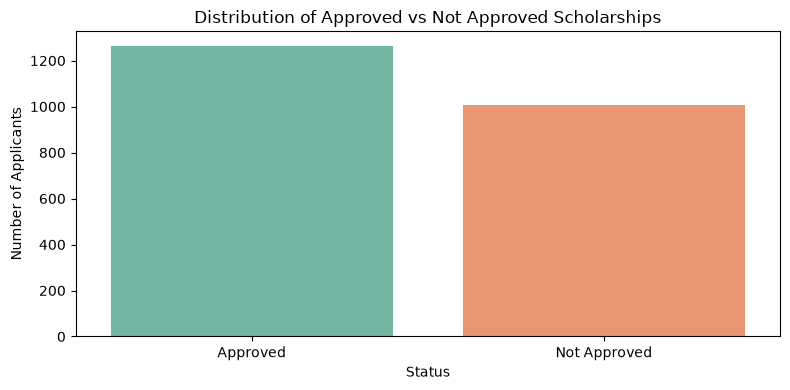

In [356]:
print("--- Missing Value Summary ---")
missing = fa.isnull().sum()
missing_pct = (missing / len(fa)) * 100
missing_fa = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct})
print(missing_fa[missing_fa['Missing Count'] > 0])

print("\n--- Target Variable ('Status') Distribution ---")
status_counts = fa['Status'].value_counts(dropna=False)
status_pct = fa['Status'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': status_counts, 'Percentage (%)': status_pct}))

# Plot Target Distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=fa, x='Status', hue='Status', palette='Set2')
plt.title('Distribution of Approved vs Not Approved Scholarships')
plt.ylabel('Number of Applicants')
plt.tight_layout()
plt.show()

Let observe the gender distribution per scholarship distribution

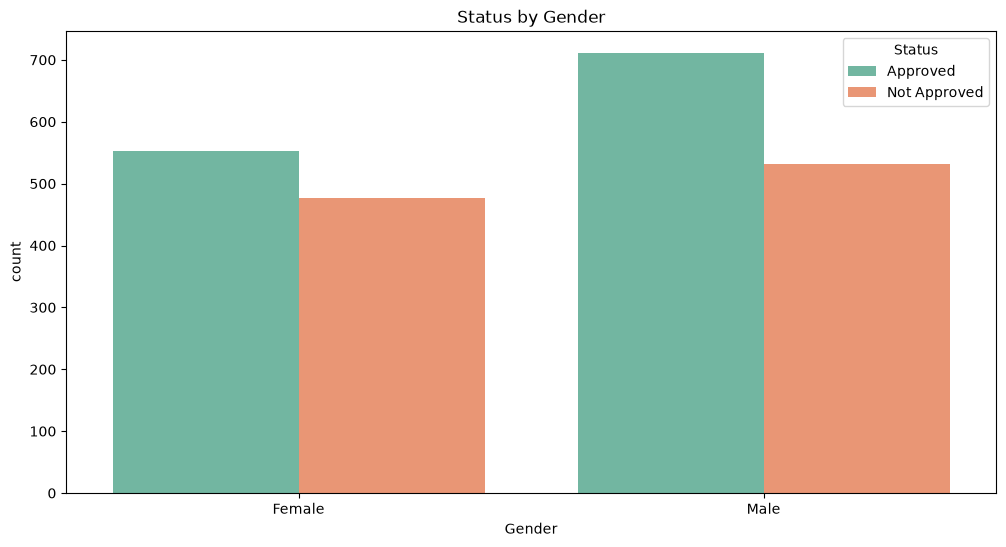

In [357]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=fa, 
    x='Gender', 
    hue='Status', 
    palette='Set2',
)
plt.title('Status by Gender')
plt.show()

Let observe the grade status awards

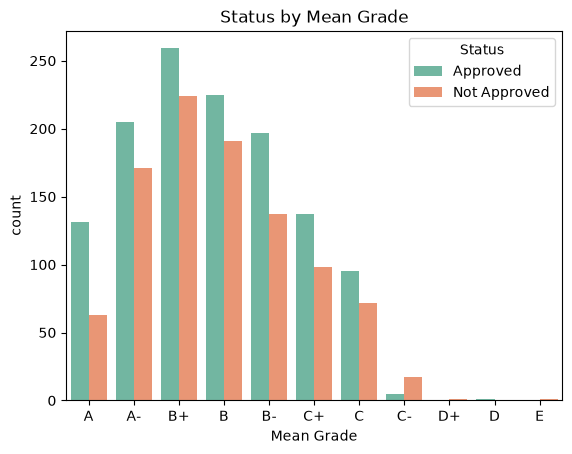

In [358]:
grade_order = ['A', 'A-', 'B+', 'B', 'B-', 'C+', 'C', 'C-', 'D+', 'D', 'D-', 'E']
# Filter order to only available grades in dataset
existing_grades = [g for g in grade_order if g in fa['Mean Grade'].unique()]
sns.countplot(
    data=fa, 
    x='Mean Grade', 
    hue='Status', 
    order=existing_grades, 
    palette='Set2'
)
plt.title('Status by Mean Grade')
plt.show()

Let plot the parent status awards 

First we will go ahead and check how many were approved and how many were not and compute its percentage ratio.

In [359]:
parent_counts = fa['Parent Status'].value_counts()
Approved_counts = fa[fa['Status'] == 'Approved']['Parent Status'].value_counts()
Not_Approved_counts = fa[fa['Status'] == 'Not Approved']['Parent Status'].value_counts()
approved_pct = (Approved_counts / parent_counts) * 100
not_approved_pct = (Not_Approved_counts / parent_counts) * 100 

pd.DataFrame(
    {
        'Parent Status': parent_counts, 
        'Approved': Approved_counts, 
        'Not Approved': Not_Approved_counts,
        'Approved %': approved_pct,
        'Not Approved %': not_approved_pct
    })

,Parent Status,Approved,Not Approved,Approved %,Not Approved %
Parent Status,,,,,
Both Parents,1919,1061,858,55.289213,44.710787
Father Deceased,222,130,92,58.558559,41.441441
Mother Deceased,87,49,38,56.321839,43.678161
Orphan,43,24,19,55.813953,44.186047


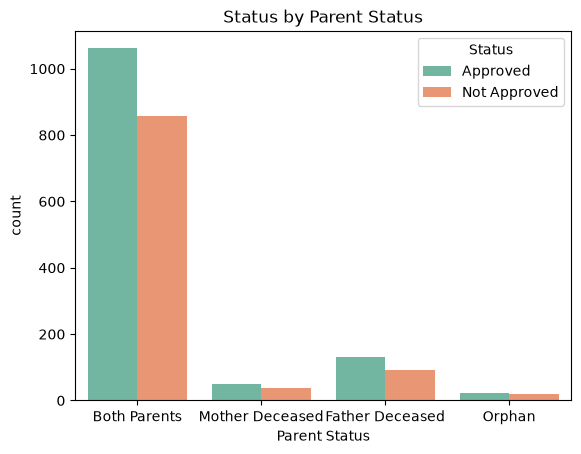

In [360]:
sns.countplot(
    data=fa, 
    x='Parent Status', 
    hue='Status',
    palette='Set2'
)
plt.title('Status by Parent Status')
plt.show()

Let analyse the top high schools to be awarded a form of scholarship

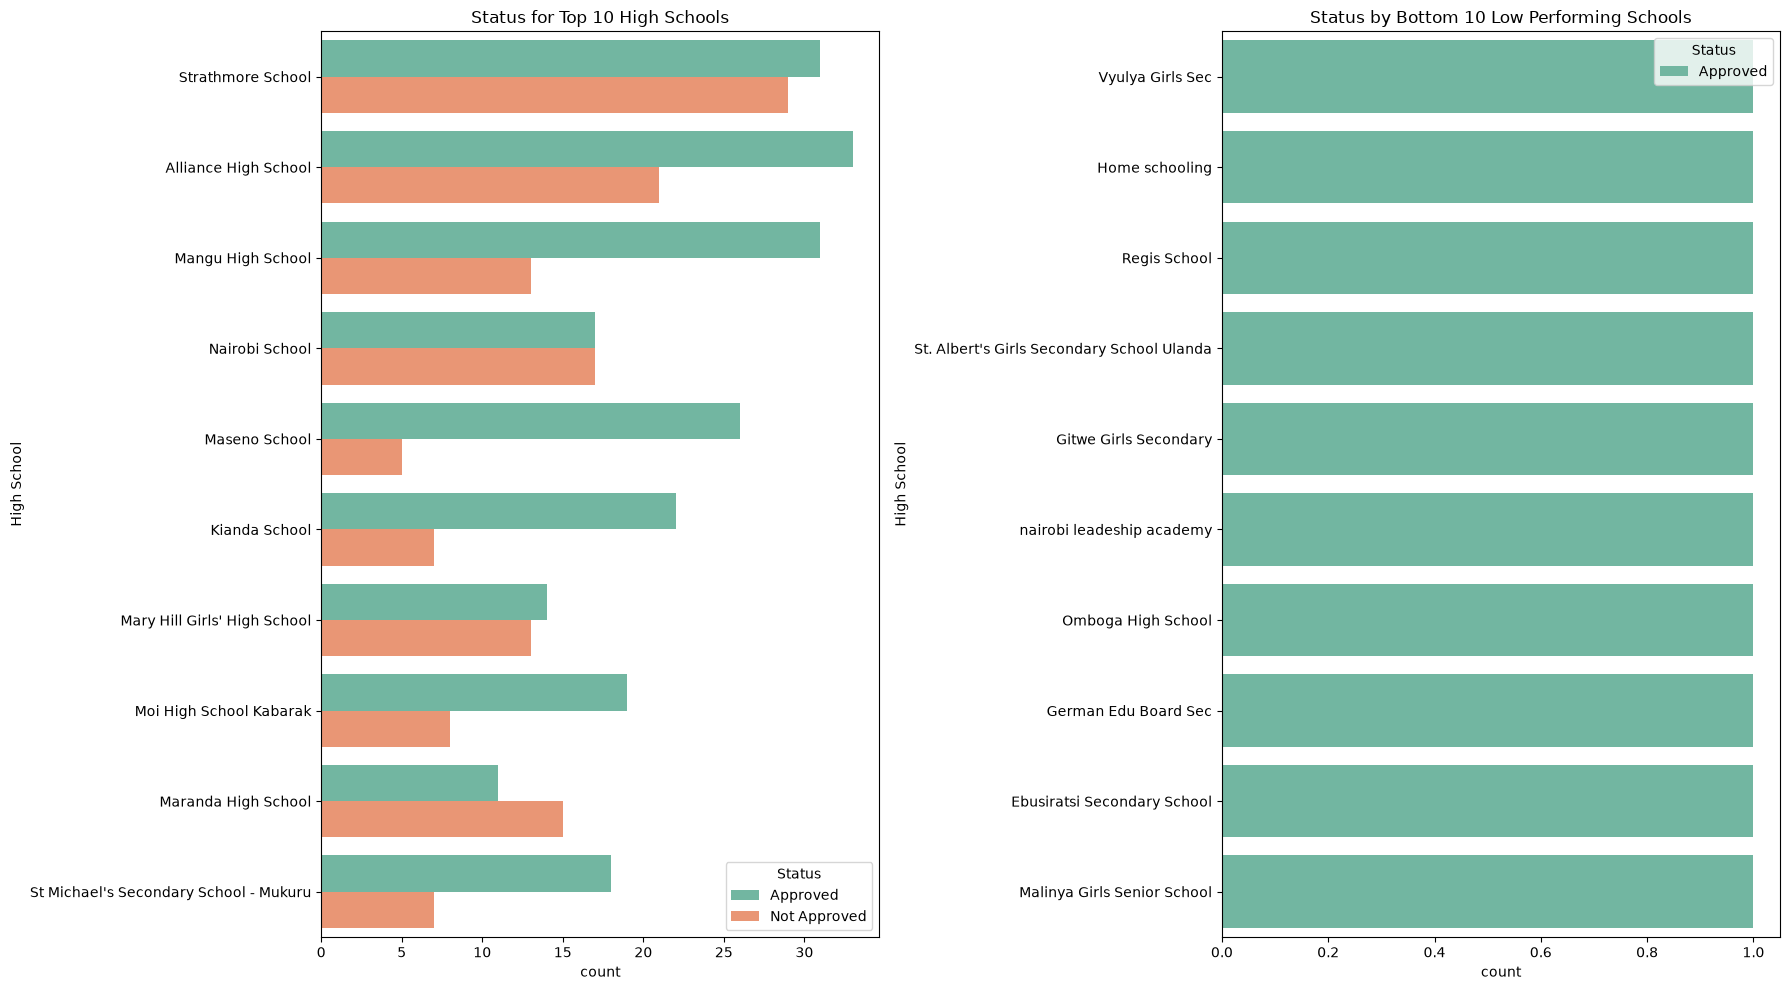

In [361]:
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

top_schools = fa['High School'].value_counts().nlargest(10).index
sns.countplot(
    data=fa[fa['High School'].isin(top_schools)], 
    y='High School',
    hue='Status',
    order=top_schools,
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title('Status for Top 10 High Schools')

bottom_schools = fa['High School'].value_counts().nsmallest(10).index
sns.countplot(
    data=fa[fa['High School'].isin(bottom_schools)], 
    y='High School',
    hue='Status',
    order=bottom_schools,
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title('Status by Bottom 10 Low Performing Schools')

plt.tight_layout()
plt.show()


LEt observe the top 5 applied course. 

In [362]:
fa['Course'].value_counts().nlargest()



Course
Bachelor of Science in Informatics and Computer Science    326
Bachelor of Commerce                                       301
Bachelor of Business Information Technology                252
Certified Public Accountant                                179
Diploma in Business Information Technology                 169
Name: count, dtype: int64

We will add the school/faculty type

In [363]:
faculty = pd.read_csv('../data/su_faculty.csv')
faculty.head()

,#,Course,School
0,1,ACCA Diploma,SIMT
1,2,Association of Chartered Certified Accountants,SIMT
2,3,Bachelor of Arts Communication,SHSS
3,4,Bachelor of Arts Development Studies and Philo...,SHSS
4,5,Bachelor of Arts International Studies,SHSS


Let use the left merge to add the School/Faculty of our courses before

In [364]:
fa = fa.merge(
    faculty[['Course', 'School']],
    on='Course',
    how='left'
)

In [365]:
fa.head()

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month,School
0,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,Both Parents,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved,2026,1,SIMT
1,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved,2026,1,SIMT
2,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,Both Parents,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved,2026,2,SIMT
3,583dd8ac280e,Male,Lenana School,B+,2025,Kiambu,Kenya,Both Parents,Jul-26,Bachelor of Science in Informatics and Compute...,,2026-04-24 10:08:50,Approved,2026,4,SCES
4,155896ac7d72,Male,Laiser Hill Academy,B-,2025,Siaya,Kenya,Both Parents,Jul-26,Bachelor of Business Information Technology,,2026-06-19 15:15:32,Approved,2026,6,SCES


Now that we have the School Categories, let plot it and see how it behaved. 

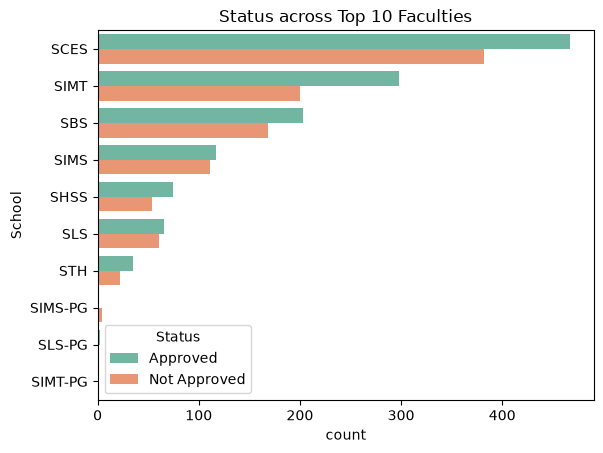

In [366]:
top_faculties = fa['School'].value_counts().nlargest(10).index
sns.countplot(
    data=fa[fa['School'].isin(top_faculties)], 
    y='School', 
    hue='Status', 
    order=top_faculties, 
    palette='Set2'
)
plt.title('Status across Top 10 Faculties')
plt.show()

Let now observe the volume of application over time.

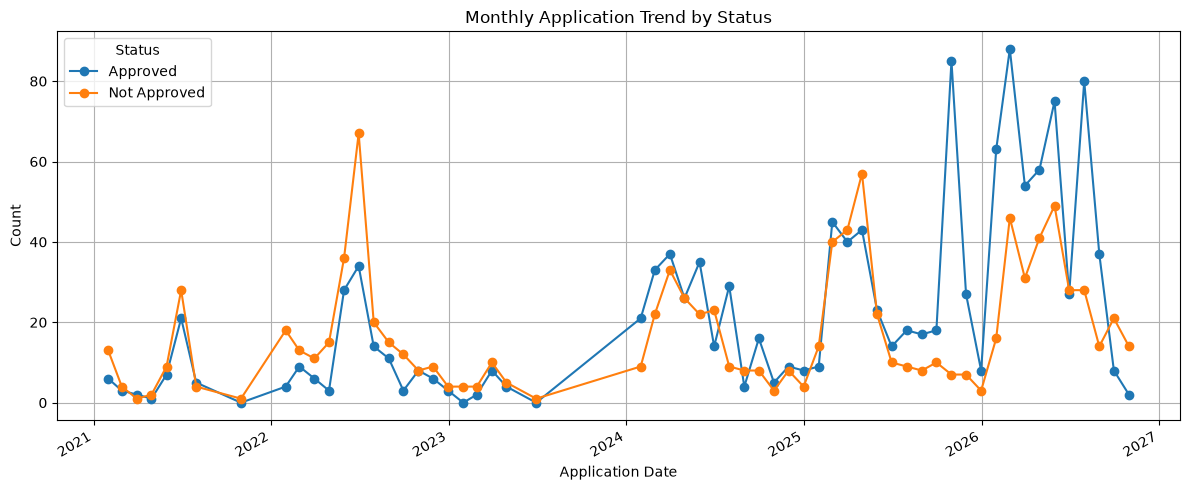

In [367]:
fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], errors='raise')

fa_data_time = (
    fa.set_index('Date Applied')
      .groupby([pd.Grouper(freq='ME'), 'Status'])
      .size()
      .unstack(fill_value=0)
)

fa_data_time.plot(kind='line', marker='o', figsize=(12, 5))
plt.title('Monthly Application Trend by Status')
plt.xlabel('Application Date')
plt.ylabel('Count')
plt.grid(True)
plt.tight_layout()
plt.show()

# Pre-treatment for Machine Learning

Let prepare the Features engineers 

#### 1. We shall convert the grade in numerical values

In [368]:
grade_map = { # Let try giving B+ and above the same result. 
    'A': 10,
    'A-': 9,
    'B+': 8,
    'B': 7,
    'B-': 6,
    'C+': 5,
    'A LEVELS': 4,
    'DIPLOMA': 3,
    'C': 2,
    'C-': 1, #From here I decided to give all the grades below C- a value of 0 since they are not considered good grades.
    'D+': 0,
    'D': 0,
    'D-': 0,
    'E': 0
}

fa['Mean Grade'] = fa['Mean Grade'].astype(str).str.strip().str.upper()
fa['mean_grade_score'] = (
    fa['Mean Grade']
    .astype(str)
    .str.strip()
    .str.upper()
    .map(grade_map)
)

In [369]:
fa['mean_grade_score'].value_counts().sort_index()

mean_grade_score
0.0       3
1.0      22
2.0     167
3.0       1
4.0      34
5.0     235
6.0     334
7.0     416
8.0     483
9.0     376
10.0    194
Name: count, dtype: int64

<Axes: xlabel='mean_grade_score'>

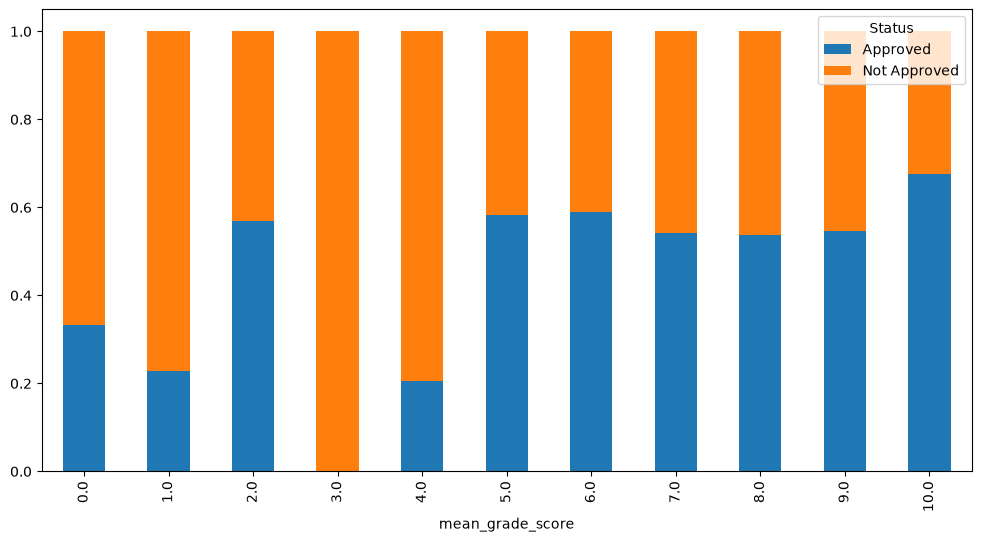

In [370]:
Table = fa[['mean_grade_score', 'Status']]
value_counts = Table.groupby('mean_grade_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, figsize=(12, 6))

In [371]:
fa.nunique()

ID                  2134
Gender                 2
High School          656
Mean Grade            13
O LEVEL YEAR          29
County                47
Country                1
Parent Status          4
Intake                71
Course                36
Siblings               1
Date Applied        2266
Status                 2
Apply_Year             6
Apply_Month           12
School                12
mean_grade_score      11
dtype: int64

#### 2. Let now create county vulnerability score

In [372]:
county_vulnerability = pd.read_csv('../data/County_GVA_Contribution_Ranked_2019_2023.csv')
county_vulnerability

,Rank,County,2019 (%),2020 (%),2021 (%),2022 (%),2023 (%),5-Year Avg (%),County Rate
0,1.0,Nairobi,27.80%,27.20%,27.20%,27.70%,27.40%,27.50%,1.0
1,2.0,Kiambu,5.70%,5.60%,5.60%,5.60%,5.50%,5.60%,1.0
2,3.0,Nakuru,4.90%,4.90%,5.20%,5.20%,5.70%,5.20%,1.0
3,4.0,Mombasa,5.00%,4.80%,4.80%,4.80%,4.80%,4.80%,1.0
4,5.0,Meru,3.30%,3.30%,3.40%,3.30%,3.50%,3.40%,1.0
5,6.0,Machakos,3.20%,3.10%,3.20%,3.20%,3.20%,3.20%,2.0
6,7.0,Kisumu,2.50%,2.50%,2.50%,2.50%,2.50%,2.50%,2.0
7,8.0,Uasin Gishu,2.40%,2.30%,2.40%,2.40%,2.50%,2.40%,2.0
8,9.0,Kakamega,2.20%,2.20%,2.20%,2.20%,2.10%,2.20%,2.0
9,10.0,Kilifi,2.10%,2.00%,2.10%,2.10%,2.10%,2.10%,6.0


In [373]:
fa['County'] = fa['County'].str.strip()
county_vulnerability['County'] = county_vulnerability['County'].str.strip()

In [374]:
fa = fa.merge(
    county_vulnerability[['County', 'County Rate']],
    on='County',
    how='left'
)

In [375]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2271 entries, 0 to 2270
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID                2271 non-null   str           
 1   Gender            2271 non-null   str           
 2   High School       2264 non-null   str           
 3   Mean Grade        2265 non-null   str           
 4   O LEVEL YEAR      2271 non-null   int64         
 5   County            2271 non-null   str           
 6   Country           2271 non-null   str           
 7   Parent Status     2271 non-null   str           
 8   Intake            2271 non-null   str           
 9   Course            2271 non-null   str           
 10  Siblings          2271 non-null   str           
 11  Date Applied      2271 non-null   datetime64[us]
 12  Status            2271 non-null   str           
 13  Apply_Year        2271 non-null   int64         
 14  Apply_Month       2271 non-null   i

In [376]:
county_null = fa.loc[fa['County Rate'].isna(), 'County']
county_null.value_counts()

County
INTERNATIONAL STUDENT    2
Name: count, dtype: int64

We have identified international students who applied for scholarship we are going to drop them since our analysis will be Kenya Focus. 


In [377]:
fa = fa[fa['County'] != 'INTERNATIONAL STUDENT'].copy()
fa['County'].value_counts().sort_index()

County
Baringo             10
Bomet                5
Bungoma             51
Busia               36
Elgeyo Marakwet      2
Embu                13
Garissa              2
Homa Bay            49
Isiolo               3
Kajiado             93
Kakamega            82
Kericho             22
Kiambu             197
Kilifi              12
Kirinyaga           16
Kisii               60
Kisumu              90
Kitui               40
Kwale                6
Laikipia            16
Lamu                 1
Machakos            83
Makueni             44
Mandera              4
Marsabit             6
Meru                24
Migori              30
Mombasa             47
Murang'a            41
Nairobi            781
Nakuru              59
Nandi               13
Narok                9
Nyamira             18
Nyandarua           20
Nyeri               43
Samburu             23
Siaya               93
Taita Taveta        17
Tana River           7
Tharaka Nithi        8
Trans Nzoia         30
Turkana              3
Uasi

<Axes: xlabel='County Rate'>

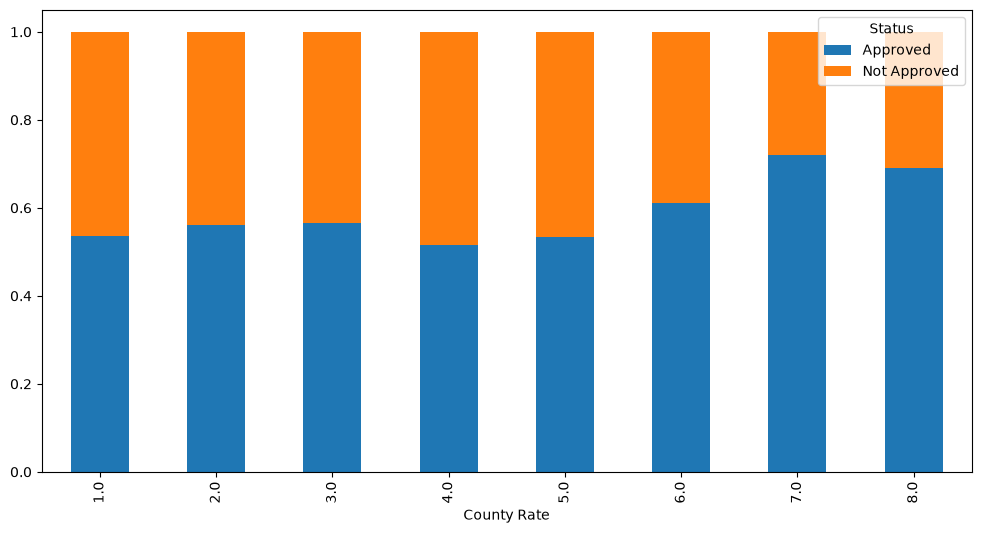

In [378]:
# Show the award 
Table = fa[['County Rate', 'Status']]
value_counts = Table.groupby('County Rate')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, 
                  figsize=(12, 6))

### We will comment this section and use the next section


#### Collins Dataset 

To rate High School Distributions

In [379]:
'''highschool = pd.read_csv('../data/2015-School-Masterlist.csv')
highschool'''

"highschool = pd.read_csv('../data/2015-School-Masterlist.csv')\nhighschool"

In [380]:
'''highschool.info()'''

'highschool.info()'

In [381]:
'''fa
highschool'''

'fa\nhighschool'

In [382]:
'''import re
from rapidfuzz import fuzz, process'''

'import re\nfrom rapidfuzz import fuzz, process'

##### Standardization and Exact Matching 


In [383]:
'''def clean_school_name(name):
  if pd.isna(name):
    return ""
  # Convert to uppercase
  name = str(name).upper()
  # Remove punctuation and special characters (keep alphanumeric and spaces)
  name = re.sub(r"[^\w\s]", "", name)
  # Normalize multiple spaces to a single space
  name = re.sub(r"\s+", " ", name).strip()
  return name


# 1. Create standardized columns for both datasets
fa["clean_school"] = fa["High School"].apply(clean_school_name)
highschool["clean_school"] = highschool["SCHOOL_NAME"].apply(clean_school_name)

# 2. Build a lookup dictionary from reference dataset for exact matches
cluster_lookup = highschool.set_index("clean_school")[
    "NAME_TYPE_SCHOOL_CLUSTER"
].to_dict()

# Map exact matches onto fao_data
fa["NAME_TYPE_SCHOOL_CLUSTER"] = fa["clean_school"].map(
    cluster_lookup
)'''

<>:7: SyntaxWarning: invalid escape sequence '\w'
<>:7: SyntaxWarning: invalid escape sequence '\w'
C:\Users\user\AppData\Local\Temp\ipykernel_24708\4020856360.py:7: SyntaxWarning: invalid escape sequence '\w'
  name = re.sub(r"[^\w\s]", "", name)


'def clean_school_name(name):\n  if pd.isna(name):\n    return ""\n  # Convert to uppercase\n  name = str(name).upper()\n  # Remove punctuation and special characters (keep alphanumeric and spaces)\n  name = re.sub(r"[^\\w\\s]", "", name)\n  # Normalize multiple spaces to a single space\n  name = re.sub(r"\\s+", " ", name).strip()\n  return name\n\n\n# 1. Create standardized columns for both datasets\nfa["clean_school"] = fa["High School"].apply(clean_school_name)\nhighschool["clean_school"] = highschool["SCHOOL_NAME"].apply(clean_school_name)\n\n# 2. Build a lookup dictionary from reference dataset for exact matches\ncluster_lookup = highschool.set_index("clean_school")[\n    "NAME_TYPE_SCHOOL_CLUSTER"\n].to_dict()\n\n# Map exact matches onto fao_data\nfa["NAME_TYPE_SCHOOL_CLUSTER"] = fa["clean_school"].map(\n    cluster_lookup\n)'

##### Fuzzy Matching for Remaining Records with Safety Thresholds

In [384]:
'''fa.columns'''

'fa.columns'

In [385]:
'''import numpy as np'''

'import numpy as np'

In [386]:
'''master_list = fa['High School']

duplicate_count = master_list.duplicated().sum()
print("Number of duplicates:", duplicate_count)

master_list = master_list.drop_duplicates()

master_list'''

'master_list = fa[\'High School\']\n\nduplicate_count = master_list.duplicated().sum()\nprint("Number of duplicates:", duplicate_count)\n\nmaster_list = master_list.drop_duplicates()\n\nmaster_list'

In [387]:
#master_list = master_list.to_frame(name="High School")

In [388]:
#master_list = master_list.dropna(subset=['High School']).copy()


In [389]:
#highschool.columns

In [390]:
#df = highschool[['SCHOOL_NAME','NAME_TYPE_SCHOOL_CLUSTER']]
#df = df.drop_duplicates()
#df

Let try and match the messy master_list with df

In [391]:
'''from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity'''

'from sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.metrics.pairwise import cosine_similarity'

In [392]:
'''# Let prepare and clean the text upper case for both df and master list

df_clean = df.dropna(subset=['SCHOOL_NAME']).copy()
df_clean['CLEAN_NAME'] = df_clean['SCHOOL_NAME'].astype(str).str.upper().str.strip()

master_clean = master_list.dropna(subset=['High School']).copy()
master_clean['CLEAN_NAME'] = master_clean['High School'].astype(str).str.upper().str.strip()'''

"# Let prepare and clean the text upper case for both df and master list\n\ndf_clean = df.dropna(subset=['SCHOOL_NAME']).copy()\ndf_clean['CLEAN_NAME'] = df_clean['SCHOOL_NAME'].astype(str).str.upper().str.strip()\n\nmaster_clean = master_list.dropna(subset=['High School']).copy()\nmaster_clean['CLEAN_NAME'] = master_clean['High School'].astype(str).str.upper().str.strip()"

In [393]:
'''# 2. Fit TF-IDF Vectorizer using character n-grams to capture substrings and typos

vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4))
df_tfidf = vectorizer.fit_transform(df_clean['CLEAN_NAME'])
master_tfidf = vectorizer.transform(master_clean['CLEAN_NAME'])'''

"# 2. Fit TF-IDF Vectorizer using character n-grams to capture substrings and typos\n\nvectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4))\ndf_tfidf = vectorizer.fit_transform(df_clean['CLEAN_NAME'])\nmaster_tfidf = vectorizer.transform(master_clean['CLEAN_NAME'])"

In [394]:
'''# Let now compute the cosine similarity 

similarity_matrix = cosine_similarity(master_tfidf, df_tfidf)
similarity_matrix'''

'# Let now compute the cosine similarity \n\nsimilarity_matrix = cosine_similarity(master_tfidf, df_tfidf)\nsimilarity_matrix'

In [395]:
'''# Let extract best matches and scores

best_match_indices = similarity_matrix.argmax(axis=1)
similarity_scores = similarity_matrix.max(axis=1)'''

'# Let extract best matches and scores\n\nbest_match_indices = similarity_matrix.argmax(axis=1)\nsimilarity_scores = similarity_matrix.max(axis=1)'

In [396]:
'''# 5. Map attributes back to your master table
master_list['Matched_Official_Name'] = df_clean['SCHOOL_NAME'].iloc[best_match_indices].values
master_list['School_Category'] = df_clean['NAME_TYPE_SCHOOL_CLUSTER'].iloc[best_match_indices].values
master_list['Similarity_Score'] = similarity_scores'''

"# 5. Map attributes back to your master table\nmaster_list['Matched_Official_Name'] = df_clean['SCHOOL_NAME'].iloc[best_match_indices].values\nmaster_list['School_Category'] = df_clean['NAME_TYPE_SCHOOL_CLUSTER'].iloc[best_match_indices].values\nmaster_list['Similarity_Score'] = similarity_scores"

In [397]:
#master_list

In [398]:
'''# LEt separate high confidence to low confidence

# Separate high-confidence matches vs low-confidence/unmatched rows
high_confidence_df = master_list[master_list['Similarity_Score'] >= 0.70].copy()
low_confidence_df = master_list[master_list['Similarity_Score'] < 0.70].copy()

print(f"Locked & Verified (>= 70%): {len(high_confidence_df)} rows")
print(f"Requires Review (< 70%): {len(low_confidence_df)} rows")'''

'# LEt separate high confidence to low confidence\n\n# Separate high-confidence matches vs low-confidence/unmatched rows\nhigh_confidence_df = master_list[master_list[\'Similarity_Score\'] >= 0.70].copy()\nlow_confidence_df = master_list[master_list[\'Similarity_Score\'] < 0.70].copy()\n\nprint(f"Locked & Verified (>= 70%): {len(high_confidence_df)} rows")\nprint(f"Requires Review (< 70%): {len(low_confidence_df)} rows")'

In [399]:
'''low_confidence_df'''

'low_confidence_df'

In [400]:
'''# Let now export low-confidence rows to csv for a rapid excel editing

# 1. Isolate the low-confidence records
low_confidence_df = master_list[master_list['Similarity_Score'] < 0.70].copy()

# 2. Export to CSV for quick editing
low_confidence_df.to_csv('../data/schools_to_review.csv', index=True)
print("Exported low-confidence rows to 'schools_to_review.csv'. Open in Excel to fix quickly!")'''

'# Let now export low-confidence rows to csv for a rapid excel editing\n\n# 1. Isolate the low-confidence records\nlow_confidence_df = master_list[master_list[\'Similarity_Score\'] < 0.70].copy()\n\n# 2. Export to CSV for quick editing\nlow_confidence_df.to_csv(\'../data/schools_to_review.csv\', index=True)\nprint("Exported low-confidence rows to \'schools_to_review.csv\'. Open in Excel to fix quickly!")'

In [401]:
'''# Let's extract tokens (words longer than 3 characters) to search the official df
def find_best_token_match(school_name, df_official):
    if pd.isna(school_name):
        return None, None, 0.0
    
    # Clean and split words
    words = [w.upper() for w in str(school_name).split() if len(w) > 3]
    if not words:
        return None, None, 0.0
    
    # Try searching with the most unique-looking word (skip generic words like 'HIGH', 'SCHOOL', 'SECONDARY')
    stop_words = {'HIGH', 'SCHOOL', 'SECONDARY', 'MIXED', 'BOYS', 'GIRLS', 'DAY', 'THE'}
    meaningful_words = [w for w in words if w not in stop_words]
    
    search_word = meaningful_words[-1] if meaningful_words else words[0]
    
    matches = df_official[df_official['SCHOOL_NAME'].str.contains(search_word, case=False, na=False)]
    if not matches.empty:
        # Return the first match found by keyword
        matched_row = matches.iloc[0]
        return matched_row['SCHOOL_NAME'], matched_row['NAME_TYPE_SCHOOL_CLUSTER'], 0.75
        
    return None, None, 0.0

# Apply to your remaining rows
for idx, row in low_confidence_df[low_confidence_df['Similarity_Score'] < 0.70].iterrows():
    match_name, match_cat, score = find_best_token_match(row['High School'], df)
    if match_name:
        low_confidence_df.loc[idx, 'Matched_Official_Name'] = match_name
        low_confidence_df.loc[idx, 'School_Category'] = match_cat
        low_confidence_df.loc[idx, 'Similarity_Score'] = score'''

"# Let's extract tokens (words longer than 3 characters) to search the official df\ndef find_best_token_match(school_name, df_official):\n    if pd.isna(school_name):\n        return None, None, 0.0\n\n    # Clean and split words\n    words = [w.upper() for w in str(school_name).split() if len(w) > 3]\n    if not words:\n        return None, None, 0.0\n\n    # Try searching with the most unique-looking word (skip generic words like 'HIGH', 'SCHOOL', 'SECONDARY')\n    stop_words = {'HIGH', 'SCHOOL', 'SECONDARY', 'MIXED', 'BOYS', 'GIRLS', 'DAY', 'THE'}\n    meaningful_words = [w for w in words if w not in stop_words]\n\n    search_word = meaningful_words[-1] if meaningful_words else words[0]\n\n    matches = df_official[df_official['SCHOOL_NAME'].str.contains(search_word, case=False, na=False)]\n    if not matches.empty:\n        # Return the first match found by keyword\n        matched_row = matches.iloc[0]\n        return matched_row['SCHOOL_NAME'], matched_row['NAME_TYPE_SCHOOL_CLUST

In [402]:
'''import re
import pandas as pd
from rapidfuzz import process, fuzz

def clean_school_name(name):
    """
    Cleans school names by converting to uppercase, stripping trailing 
    metadata/IDs (e.g., '-6818 NAIROBI'), and removing common boilerplate 
    words that cause false positive matches.
    """
    if pd.isna(name):
        return ""
    text = str(name).upper()
    
    # 1. Remove trailing ID codes and locations like "-6818 NAIROBI" or "- 24 NDHIWA"
    text = re.sub(r'-\s*\d+.*$', '', text)
    
    # 2. Remove common boilerplate words that dominate character-based matching
    noise_words = ['SECONDARY', 'SCHOOL', 'HIGH', 'BOYS', 'GIRLS', 'MIXED', 'DAY', 'BOARDING']
    words = [w for w in text.split() if w not in noise_words]
    
    return " ".join(words).strip()


# ==========================================
# STEP 1: PREPARE AND CLEAN BOTH DATASETS
# ==========================================
df_clean = df.dropna(subset=['SCHOOL_NAME']).copy()
df_clean['SEARCH_NAME'] = df_clean['SCHOOL_NAME'].apply(clean_school_name)

master_clean = master_list.dropna(subset=['High School']).copy()
master_clean['SEARCH_NAME'] = master_clean['High School'].apply(clean_school_name)


# ==========================================
# STEP 2: FUZZY MATCH USING RAPIDFUZZ (TOKEN SET)
# ==========================================
matched_official_names = []
matched_categories = []
similarity_scores = []

# Extract reference arrays for fast index lookup
official_names = df_clean['SCHOOL_NAME'].values
official_categories = df_clean['NAME_TYPE_SCHOOL_CLUSTER'].values
search_choices = df_clean['SEARCH_NAME'].tolist()

for query in master_clean['SEARCH_NAME']:
    if not query:
        matched_official_names.append(None)
        matched_categories.append(None)
        similarity_scores.append(0.0)
        continue
        
    # Find the best match using token_set_ratio (ignores word order & extra noise words)
    result = process.extractOne(
        query, 
        search_choices, 
        scorer=fuzz.token_set_ratio
    )
    
    if result:
        matched_text, score, idx = result
        # Convert RapidFuzz score from 0-100 scale to 0.0-1.0 scale
        norm_score = score / 100.0
        
        matched_official_names.append(official_names[idx])
        matched_categories.append(official_categories[idx])
        similarity_scores.append(norm_score)
    else:
        matched_official_names.append(None)
        matched_categories.append(None)
        similarity_scores.append(0.0)


# ==========================================
# STEP 3: MAP ATTRIBUTES BACK TO MASTER LIST SAFELY
# ==========================================
master_list['Matched_Official_Name'] = None
master_list['School_Category'] = None
master_list['Similarity_Score'] = 0.0

# Assign results using original row indexes to prevent length mismatch errors
master_list.loc[master_clean.index, 'Matched_Official_Name'] = matched_official_names
master_list.loc[master_clean.index, 'School_Category'] = matched_categories
master_list.loc[master_clean.index, 'Similarity_Score'] = similarity_scores


# ==========================================
# STEP 4: SEPARATE HIGH VS LOW CONFIDENCE
# ==========================================
high_confidence_df = master_list[master_list['Similarity_Score'] >= 0.75].copy()
low_confidence_df = master_list[master_list['Similarity_Score'] < 0.75].copy()

print(f"Locked & Verified (>= 75%): {len(high_confidence_df)} rows")
print(f"Requires Review (< 75%): {len(low_confidence_df)} rows")

# Optional: Export low confidence rows for human inspection
#low_confidence_df[['High School', 'Matched_Official_Name', 'Similarity_Score']].to_csv('../data/schools_to_review.csv', index=False)'''

<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\s'
C:\Users\user\AppData\Local\Temp\ipykernel_24708\2639131120.py:16: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub(r'-\s*\d+.*$', '', text)


'import re\nimport pandas as pd\nfrom rapidfuzz import process, fuzz\n\ndef clean_school_name(name):\n    """\n    Cleans school names by converting to uppercase, stripping trailing \n    metadata/IDs (e.g., \'-6818 NAIROBI\'), and removing common boilerplate \n    words that cause false positive matches.\n    """\n    if pd.isna(name):\n        return ""\n    text = str(name).upper()\n\n    # 1. Remove trailing ID codes and locations like "-6818 NAIROBI" or "- 24 NDHIWA"\n    text = re.sub(r\'-\\s*\\d+.*$\', \'\', text)\n\n    # 2. Remove common boilerplate words that dominate character-based matching\n    noise_words = [\'SECONDARY\', \'SCHOOL\', \'HIGH\', \'BOYS\', \'GIRLS\', \'MIXED\', \'DAY\', \'BOARDING\']\n    words = [w for w in text.split() if w not in noise_words]\n\n    return " ".join(words).strip()\n\n\n# ==========================================\n# STEP 1: PREPARE AND CLEAN BOTH DATASETS\n# ==========================================\ndf_clean = df.dropna(subset=[\'SCHOOL

In [403]:
#low_confidence_df

In [404]:
#low_confidence_df.to_csv('../data/low_confidence.csv', index=False)


In [405]:
#df['NAME_TYPE_SCHOOL_CLUSTER'].value_counts()

In [406]:
#master_list['School_Category'].value_counts()

### Let continue from here

We will use the the school tier from the LLM architecture. 


We will start by inputing the High school category column before inputing anything else.

In [407]:
high_school = pd.read_csv("../data/school_classifications.csv")
high_school.head()

,High School,High School Category,confidence,reason
0,A.I.C Ebenezer Academy,PRIVATE,0.8,The name 'Academy' suggests it is a private in...
1,Abba Salama Academy,PRIVATE,0.8,The name 'Academy' is often associated with pr...
2,Acacia Crest Senior School,PRIVATE,0.8,The name 'Acacia Crest Senior School' suggests...
3,ACADEMIA SCHOOL OF KIBERA,PRIVATE,0.8,The name 'ACADEMIA SCHOOL' suggests a private ...
4,Aga Khan Academy,PRIVATE,1.0,The Aga Khan Academy is a well-known private s...


In [408]:
fa['High School'] = fa['High School'].str.strip()
high_school['High School'] = high_school['High School'].str.strip()

In [409]:
fa = fa.merge(
    high_school[['High School', 'High School Category']],
    on='High School',
    how='left'
)

In [410]:
fa['High School Category'].value_counts()

High School Category
NATIONAL         924
SUB_COUNTY       609
PRIVATE          598
UNKNOWN           78
COUNTY            14
INTERNATIONAL      4
Name: count, dtype: int64

In [411]:
# Let create high school category score based on the high school category.
# I will assign 1 to international, 2 to national, 3 to private, 4 to unknown, 5 to county, and 6 to sub-county. 
# The Higher the score, the better the school category.

school_category_map = {
    'INTERNATIONAL': 0,
    'NATIONAL': 2,
    'PRIVATE': 3,
    'UNKNOWN': 4,
    'COUNTY': 5,
    'SUB_COUNTY': 6
}

fa['high_school_category_score'] = fa['High School Category'].map(school_category_map)

<Axes: xlabel='high_school_category_score'>

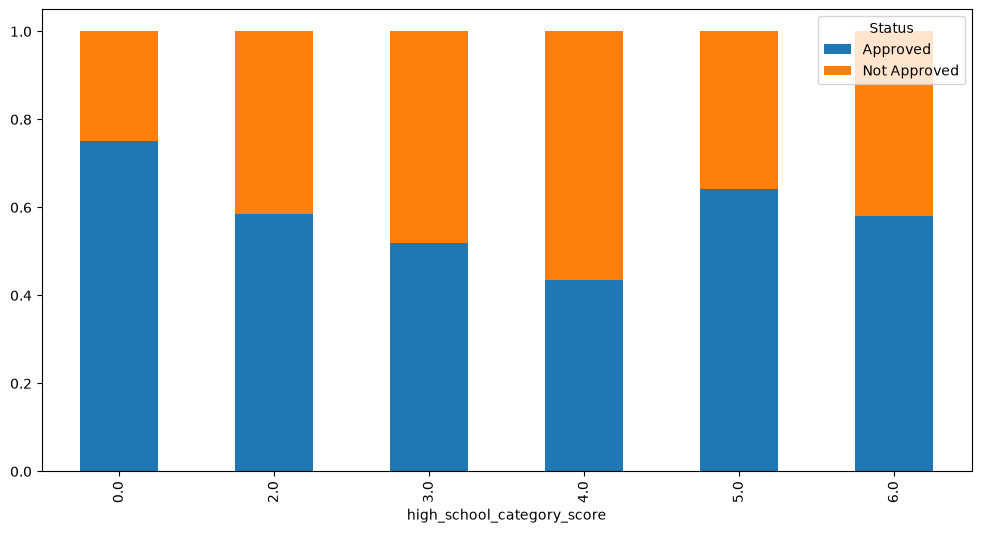

In [412]:
Table1 = fa[['high_school_category_score', 'Status']]
value_counts = Table1.groupby('high_school_category_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, 
                  figsize=(12, 6))

In [413]:
#show high school where highs school category is international 

fa[fa['High School Category'] == 'INTERNATIONAL']

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month,School,mean_grade_score,County Rate,High School Category,high_school_category_score
148,e61acf933f25,Female,Rophine Field International,B,2025,Machakos,Kenya,Both Parents,Jan-26,Diploma in International Relations FT,,2026-02-05 22:55:27,Approved,2026,2,SIMT,7.0,2.0,INTERNATIONAL,0.0
158,0fe3439ce90e,Male,Brookhurst International School,B,2024,Embu,Kenya,Both Parents,Jul-26,Bachelor of Business Information Technology,,2026-05-28 09:21:33,Approved,2026,5,SCES,7.0,4.0,INTERNATIONAL,0.0
996,e720c115ea7c,Male,British International School,B+,2023,Mombasa,Kenya,Father Deceased,Jul-24,Bachelor of Science in Informatics and Compute...,,2024-05-28 12:41:15,Approved,2024,5,SCES,8.0,1.0,INTERNATIONAL,0.0
1470,2b84df68b905,Male,Crawford International School Kenya,A-,2024,Nakuru,Kenya,Father Deceased,Jul-25,Bachelor of Science in Electrical and Electron...,,2026-02-05 11:18:35,Not Approved,2026,2,SCES,9.0,1.0,INTERNATIONAL,0.0


In [414]:
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month,School,mean_grade_score,County Rate,High School Category,high_school_category_score
0,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,Both Parents,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved,2026,1,SIMT,5.0,1.0,PRIVATE,3.0
1,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved,2026,1,SIMT,2.0,4.0,SUB_COUNTY,6.0
2,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,Both Parents,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved,2026,2,SIMT,10.0,1.0,SUB_COUNTY,6.0
3,583dd8ac280e,Male,Lenana School,B+,2025,Kiambu,Kenya,Both Parents,Jul-26,Bachelor of Science in Informatics and Compute...,,2026-04-24 10:08:50,Approved,2026,4,SCES,8.0,1.0,NATIONAL,2.0
4,155896ac7d72,Male,Laiser Hill Academy,B-,2025,Siaya,Kenya,Both Parents,Jul-26,Bachelor of Business Information Technology,,2026-06-19 15:15:32,Approved,2026,6,SCES,6.0,6.0,PRIVATE,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2317,40dd450deccf,Female,Kenya High Girls,A-,2021,Migori,Kenya,Both Parents,Jul-21,Bachelor of Laws,,2021-06-19 20:15:35,Not Approved,2021,6,SLS,9.0,5.0,NATIONAL,2.0
2318,64005080de35,Female,Aga Khan High school,B,2021,Mombasa,Kenya,Both Parents,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-06-25 17:36:55,Not Approved,2021,6,SCES,7.0,1.0,PRIVATE,3.0
2319,64005080de35,Female,Aga Khan High school,B,2021,Mombasa,Kenya,Both Parents,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-06-25 17:36:55,Not Approved,2021,6,SCES,7.0,1.0,PRIVATE,3.0
2320,430c452ce031,Male,Maseno School,B+,2019,Kiambu,Kenya,Father Deceased,Jul-21,Bachelor of Laws,,2021-06-21 21:42:05,Not Approved,2021,6,SLS,8.0,1.0,NATIONAL,2.0


4. We will be prioritizing certain year compared to others

The rational here is to create a feature which gives priority to student have just completed their KCSE compared to the ones who completed the KCSE a little bit later.

The fresh KCSE candidates will be given more priority compared to someone who completed longtime ago.

In [415]:
fa['O LEVEL YEAR'] = fa['O LEVEL YEAR'].astype('Int64')

In [416]:
#first let group by Year and check the O level year distribution

gap = fa['Apply_Year'] - fa['O LEVEL YEAR']

conditions = [
    (gap <= 1),  # Gap of less than or equal to 1 year
    (gap == 2), #& (gap < 3),  # Gap between 2 and 3 years
    (gap == 3) , # & (gap < 4),  # Gap between 3 and 4 years
    (gap >= 4) & (gap <= 5),  # Gap between 4 and 5 years
    (gap >= 6)& (gap <= 7),  # Gap between 6 and 7 years
    (gap >= 8)  # Gap of 8 years or more
]
choices = [5, 4,3,2, 1,0]

fa["o_level_apply_score"] = np.select(
    conditions, choices, default=np.nan
)

In [417]:
fa[['Apply_Year', 'O LEVEL YEAR', 'o_level_apply_score','Status']]

,Apply_Year,O LEVEL YEAR,o_level_apply_score,Status
0,2026,2020,1.0,Approved
1,2026,2016,0.0,Approved
2,2026,2025,5.0,Approved
3,2026,2025,5.0,Approved
4,2026,2025,5.0,Approved
...,...,...,...,...
2317,2021,2021,5.0,Not Approved
2318,2021,2021,5.0,Not Approved
2319,2021,2021,5.0,Not Approved
2320,2021,2019,4.0,Not Approved


<Axes: xlabel='o_level_apply_score'>

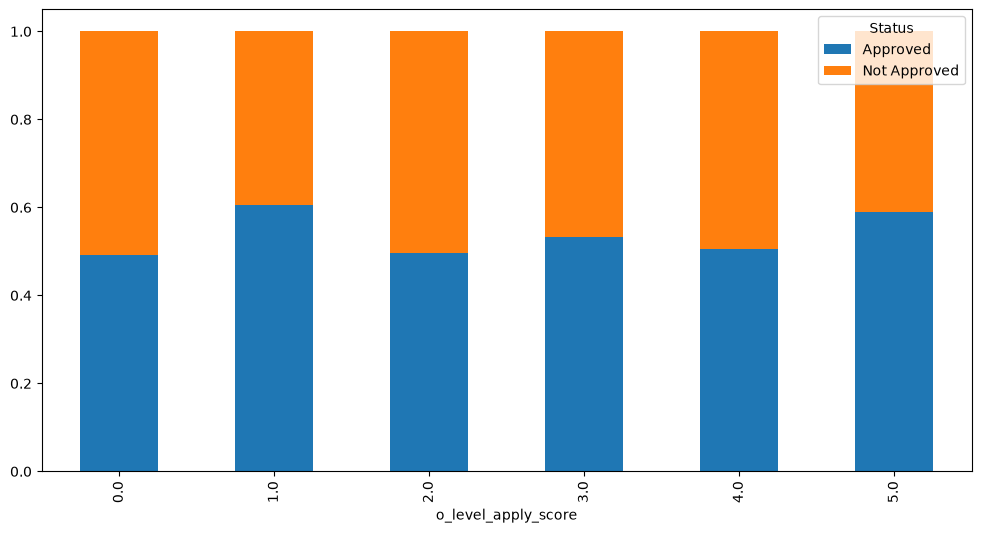

In [418]:
Table2 = fa[['o_level_apply_score', 'Status']]
value_counts = Table2.groupby('o_level_apply_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, 
                  figsize=(12, 6))

5. Let create the parent status score

Both Parents with 1, Father Deceased and Mother Deceased 2 and orphan 3

In [419]:
fa['parent_status_score'] = (
    fa['Parent Status'].map({
        'Both Parents': 1,
        'Father Deceased': 3,
        'Mother Deceased': 2,
        'Orphan': 4
    })
)

<Axes: xlabel='parent_status_score'>

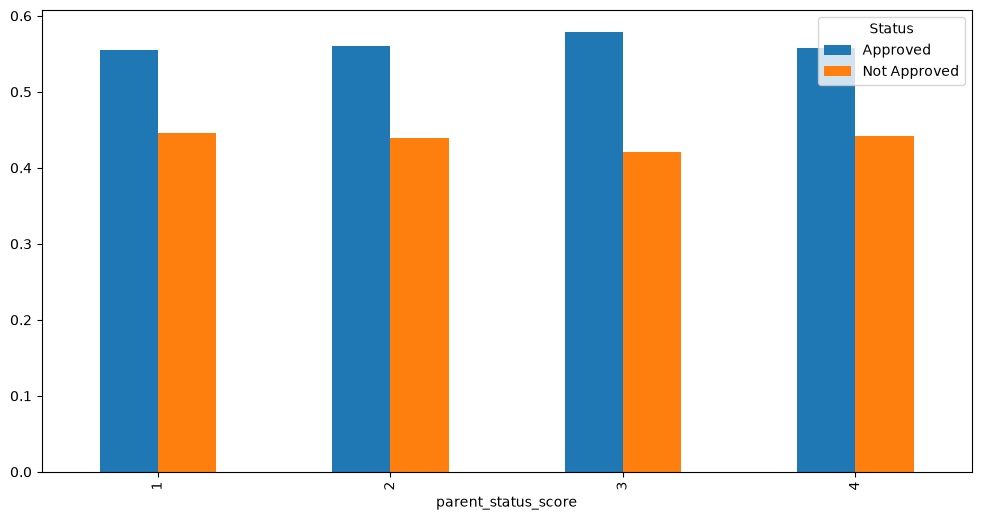

In [420]:
Table1 = fa[['parent_status_score', 'Status']]
value_counts = Table1.groupby('parent_status_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=False, 
                  figsize=(12, 6))

In [421]:
fa[['Parent Status', 'parent_status_score']]

,Parent Status,parent_status_score
0,Both Parents,1
1,Mother Deceased,2
2,Both Parents,1
3,Both Parents,1
4,Both Parents,1
...,...,...
2317,Both Parents,1
2318,Both Parents,1
2319,Both Parents,1
2320,Father Deceased,3


Let create a rate for Course eligibility score where if undergraduate, diploma plus CPA we give a 1 if not a 0 

In [422]:
# This is to help us create a feature for eligible or not based on 
# the course the student is doing. with if Degree, Diplomas + CPA = 1 otherwise give 0

import pandas as pd
import numpy as np
import re

# Work on a separate copy to preserve the original notebook
def classify_programme(course):
    if pd.isna(course) or not str(course).strip():
        return "Unclassified", None

    name = str(course).upper()
    name = re.sub(r"[.\-']", "", name)
    name = " ".join(name.split())

    # CPA remains eligible, including CPA certificates
    if re.search(
        r"\bCPA\b|CERTIFIED PUBLIC ACCOUNTANT", name
    ):
        return "CPA", 1

    # Master's programmes
    if re.search(
        r"\b(MASTER|MASTERS|MSC|MBA|LLM|MPHIL)\b",
        name
    ):
        return "Masters", 0

    # Postgraduate diplomas need separate policy verification
    if "POSTGRADUATE DIPLOMA" in name:
        return "Unclassified", None

    # Other certificates
    if re.search(r"\b(CERTIFICATE|Association of Chartered Certified Accountants)\b", name):
        return "Certificate", 0

    # Undergraduate degrees
    if re.search(
        r"\b(BACHELOR|BACHELORS|BSC|BCOM|BBIT|LLB|BBA)\b",
        name
    ):
        return "Undergraduate Degree", 1

    # Other professional qualifications
    other_professional_programmes = {
        "ASSOCIATION OF CHARTERED CERTIFIED ACCOUNTANTS",
        "CHARTERED FINANCIAL ANALYST",
        "CHARTERED INSTITUTE OF MARKETING"
    }

    if name in other_professional_programmes:
        return "Other Professional Qualification", 0

    # Diplomas
    if re.search(r"\bDIPLOMA\b", name):
        return "Diploma", 1

    return "Unclassified", None


fa[
    ["programme_level", "programme_eligible"]
] = pd.DataFrame(
    fa["Course"].apply(classify_programme).tolist(),
    index=fa.index
)

# Display programme classification
print("Programme distribution:")
display(fa["programme_level"].value_counts())

print("\nEligibility distribution:")
display(
    fa["programme_eligible"].value_counts(
        dropna=False
    )
)

# Inspect programmes requiring manual classification
print("\nUnclassified programmes:")
display(
    fa.loc[
        fa["programme_eligible"].isna(), "Course"
    ].value_counts()
)


Programme distribution:


programme_level
Undergraduate Degree                1812
Diploma                              303
CPA                                  179
Other Professional Qualification      16
Masters                               12
Name: count, dtype: int64


Eligibility distribution:


programme_eligible
1    2294
0      28
Name: count, dtype: int64


Unclassified programmes:


Series([], Name: count, dtype: int64)

In [423]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2322 entries, 0 to 2321
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID                          2322 non-null   str           
 1   Gender                      2322 non-null   str           
 2   High School                 2315 non-null   str           
 3   Mean Grade                  2316 non-null   str           
 4   O LEVEL YEAR                2322 non-null   Int64         
 5   County                      2322 non-null   str           
 6   Country                     2322 non-null   str           
 7   Parent Status               2322 non-null   str           
 8   Intake                      2322 non-null   str           
 9   Course                      2322 non-null   str           
 10  Siblings                    2322 non-null   str           
 11  Date Applied                2322 non-null   datetime64[us]
 12  Sta

In [424]:
fa['Course'].value_counts()

Course
Bachelor of Science in Informatics and Computer Science          341
Bachelor of Commerce                                             304
Bachelor of Business Information Technology                      262
Certified Public Accountant                                      179
Bachelor of Science in Electrical and Electronics Engineering    172
Diploma in Business Information Technology                       169
Bachelor of Laws                                                 139
Bsc. Computer Networks and Cybersecurity                          97
Bachelor of Arts International Studies                            94
Bachelor of Business Science in Financial Engineering             80
BSc. Statistics and Data Science (BSc. SDS)                       61
Diploma in International Relations FT                             56
Bachelor of Business Science in Financial Economics               53
Diploma in Business Management                                    50
Bachelor of Science in Hosp

In [425]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2322 entries, 0 to 2321
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID                          2322 non-null   str           
 1   Gender                      2322 non-null   str           
 2   High School                 2315 non-null   str           
 3   Mean Grade                  2316 non-null   str           
 4   O LEVEL YEAR                2322 non-null   Int64         
 5   County                      2322 non-null   str           
 6   Country                     2322 non-null   str           
 7   Parent Status               2322 non-null   str           
 8   Intake                      2322 non-null   str           
 9   Course                      2322 non-null   str           
 10  Siblings                    2322 non-null   str           
 11  Date Applied                2322 non-null   datetime64[us]
 12  Sta

#### This will mark the end of our Features of importance. 

In [426]:
fa['Status'] = fa['Status'].map({'Approved': 1, 'Not Approved': 0})

<Axes: >

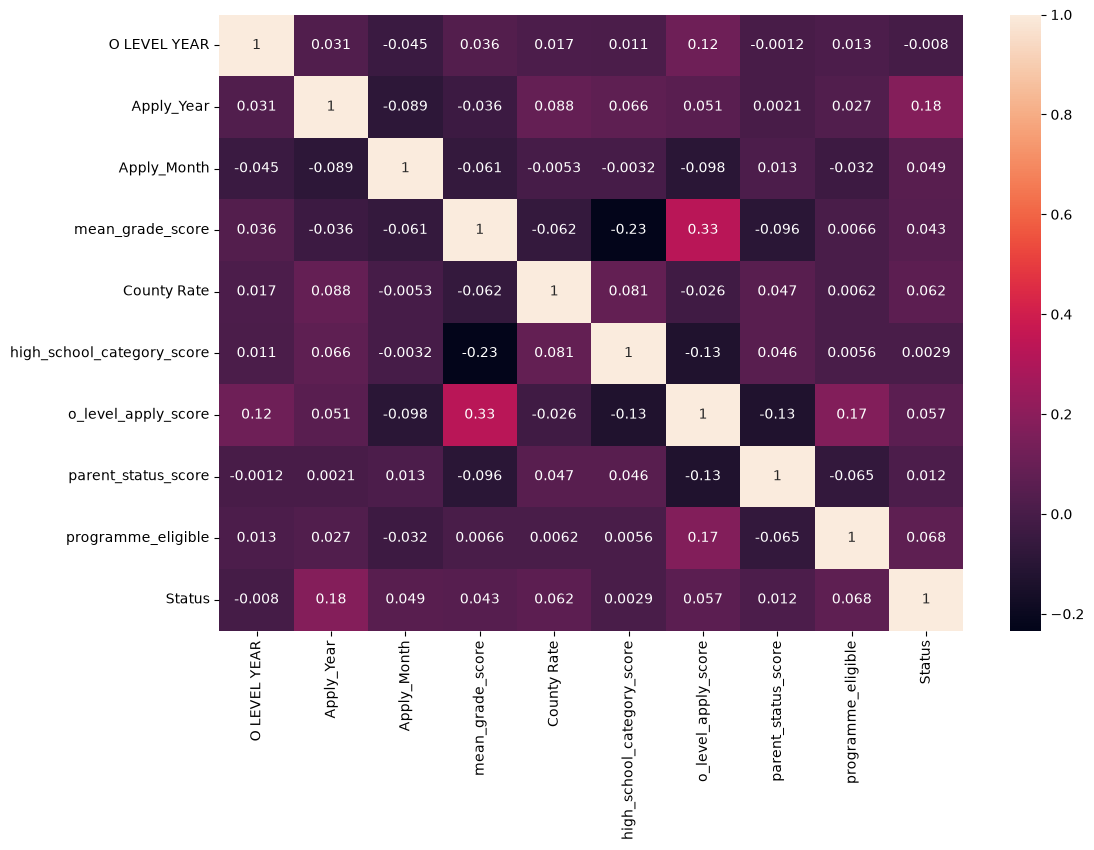

In [427]:
corr = fa.select_dtypes(include='number').corr()

cols = [c for c in corr.columns if c != 'Status'] + ['Status']
corr = corr.loc[cols, cols]

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=corr,
    annot=True,
)

In [1254]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2322 entries, 0 to 2321
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID                          2322 non-null   str           
 1   Gender                      2322 non-null   str           
 2   High School                 2315 non-null   str           
 3   Mean Grade                  2316 non-null   str           
 4   O LEVEL YEAR                2322 non-null   Int64         
 5   County                      2322 non-null   str           
 6   Country                     2322 non-null   str           
 7   Parent Status               2322 non-null   str           
 8   Intake                      2322 non-null   str           
 9   Course                      2322 non-null   str           
 10  Siblings                    2322 non-null   str           
 11  Date Applied                2322 non-null   datetime64[us]
 12  Sta

In [1861]:
fa['programme_eligible'].value_counts()

programme_eligible
1    2294
0      28
Name: count, dtype: int64

1. Let separate the train and target variables. 

In [1812]:
X = fa.drop(columns=['ID', 'Gender', 'High School', 
             #'Mean Grade', 
             #'O LEVEL YEAR', #'County',
             'Country', 
             #'Parent Status', 
             'Intake', 
             'Course', 'Siblings','Date Applied', 'Status', 
             #'Apply_Year', 
             'Apply_Month', 
             'School', #'mean_grade_score', 'County Rate', 'High School Category',
             #'high_school_category_score', 
             #'o_level_apply_score', 
             #'parent_status_score',
             'programme_level',
             #'programme_eligible'

    ]
)

y = fa['Status']

In [1813]:
# Since we have o level year, apply year and o level apply year score, 
# we can drop the o level year and apply year 
# since they helped us get the o level apply year score.

X = X.drop(columns=['County', 'Mean Grade'])

In [1814]:
numerical_cols = X.select_dtypes(include='number').columns
categorical_cols = X.select_dtypes(include='object').columns

print(f'Numerical Columns: {list(numerical_cols)}')
print(f'Categorical Columns: {list(categorical_cols)}')

Numerical Columns: ['O LEVEL YEAR', 'Apply_Year', 'mean_grade_score', 'County Rate', 'high_school_category_score', 'o_level_apply_score', 'parent_status_score', 'programme_eligible']
Categorical Columns: ['Parent Status', 'High School Category']


C:\Users\user\AppData\Local\Temp\ipykernel_24708\2421744389.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include='object').columns


**Let Create a Pipeline**

In [1815]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (RobustScaler,
                                   OneHotEncoder
                                   )

from sklearn.impute import SimpleImputer


# create data types 

#numerical cols 

numerical_pipelines = Pipeline(steps=[
    ('num_imputer', SimpleImputer(strategy='median')),
    ('num_scaler', RobustScaler())
])

#Categorical cols 

categorical_pipelines = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

transformer = ColumnTransformer(transformers=[
    ('num', numerical_pipelines, numerical_cols),
    ('cat', categorical_pipelines, categorical_cols)
])

transformer

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [1816]:
# LEt audit our cell before splitting
# Audit repeated applications for the same ID and Course

duplicate_records = fa[
    fa.duplicated(
        subset=["ID", "Course"],
        keep=False
    )
].copy()

# Summarize repeated ID + Course combinations
duplicate_summary = (
    duplicate_records
    .groupby(["ID", "Course"], dropna=False)
    .agg(
        Records=("Status", "size"),
        Different_Outcomes=("Status", "nunique"),
        Different_Dates=("Date Applied", "nunique")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

print("Repeated ID + Course combinations:",
      len(duplicate_summary))

print("Conflicting outcomes:",
      (duplicate_summary["Different_Outcomes"] > 1).sum())

print("Exact duplicate rows:",
      fa.duplicated().sum())

display(duplicate_summary)


Repeated ID + Course combinations: 28
Conflicting outcomes: 0
Exact duplicate rows: 53


,ID,Course,Records,Different_Outcomes,Different_Dates
0,1573b4ebebe0,Bachelor of Science in Informatics and Compute...,3,1,1
1,18e9a0ca8557,Bachelor of Laws,3,1,1
2,281fde618d05,Bachelor of Business Science in Financial Econ...,3,1,1
4,4542794b1470,Bachelor of Laws,3,1,1
8,5b61e287ca28,Bachelor of Science in Informatics and Compute...,3,1,1
5,459901248494,BSc. Statistics and Data Science (BSc. SDS),3,1,1
6,56045f5c1cb9,Bachelor of Laws,3,1,1
7,57960d9bea4c,Bachelor of Laws,3,1,1
10,5d73b4b332b7,Bachelor of Science in Informatics and Compute...,3,1,1
9,5b914def163d,Bachelor of Business Information Technology,3,1,1


In [1817]:
# We will replace our previous random split with group splitting 

'''from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)'''


from sklearn.model_selection import StratifiedGroupKFold

# ====================================================
# 1. ALIGN FEATURES, TARGET AND STUDENT IDS
# ====================================================

assert len(X) == len(y) == len(fa), (
    "X, y and fa must contain the same records."
)

# These X and y were constructed from fa
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

groups = (
    fa["ID"]
    .astype("string")
    .str.strip()
    .reset_index(drop=True)
)

if groups.isna().any() or groups.eq("").any():
    raise ValueError("Missing Student IDs detected.")

# ====================================================
# 2. STRATIFIED GROUP-AWARE SPLIT
# ====================================================

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

# Create training and testing datasets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# ====================================================
# 3. VERIFY NO STUDENT OVERLAP
# ====================================================

train_students = set(groups.iloc[train_idx])
test_students = set(groups.iloc[test_idx])

overlap = train_students.intersection(test_students)

print("GROUP-AWARE TRAIN / TEST SPLIT")
print("-" * 40)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Unique training students:", len(train_students))
print("Unique testing students:", len(test_students))

print("Overlapping Student IDs:", len(overlap))

print("\nTraining approval rate:",
      round(y_train.mean(), 4))

print("Testing approval rate:",
      round(y_test.mean(), 4))

assert len(overlap) == 0, (
    "Data leakage: Student IDs overlap!"
)

print("\nGroup-aware split validation PASSED.")



GROUP-AWARE TRAIN / TEST SPLIT
----------------------------------------
Training records: 1856
Testing records: 466
Unique training students: 1703
Unique testing students: 429
Overlapping Student IDs: 0

Training approval rate: 0.5571
Testing approval rate: 0.5579

Group-aware split validation PASSED.


Now that we have split our data let transform the data

In [1818]:
X_transformed = transformer.fit_transform(X_train)
X_test_transformed = transformer.transform(X_test)

SInce we have finalizing transforming our data set, let onw go ahead and 

**train our models.** 



1. We will train using Logist regression and will be used as our baseline model. 


In [1819]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_transformed, y_train) #Training
lr_model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [1820]:
# Let evaluate the Logistic Regression model 
from sklearn.metrics import classification_report, confusion_matrix, f1_score 

y_pred_lr = lr_model.predict(X_test_transformed)

In [1821]:
f1_score(y_test, y_pred_lr)

0.6901172529313233

In [1822]:
print(confusion_matrix(y_test, y_pred_lr))

[[ 75 131]
 [ 54 206]]


In [1823]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.58      0.36      0.45       206
           1       0.61      0.79      0.69       260

    accuracy                           0.60       466
   macro avg       0.60      0.58      0.57       466
weighted avg       0.60      0.60      0.58       466



In [1824]:
lr_df= pd.DataFrame(lr_model.coef_[0], 
                   columns=['importance'], 
                   index=transformer.get_feature_names_out())
lr_df.sort_values(by='importance', ascending=False).head(10)

,importance
num__programme_eligible,1.248183
cat__High School Category_SUB_COUNTY,0.539369
num__Apply_Year,0.478962
cat__High School Category_COUNTY,0.383699
num__County Rate,0.149742
cat__Parent Status_Mother Deceased,0.124061
num__mean_grade_score,0.098414
num__parent_status_score,0.070711
num__o_level_apply_score,0.051121
cat__Parent Status_Orphan,0.049075


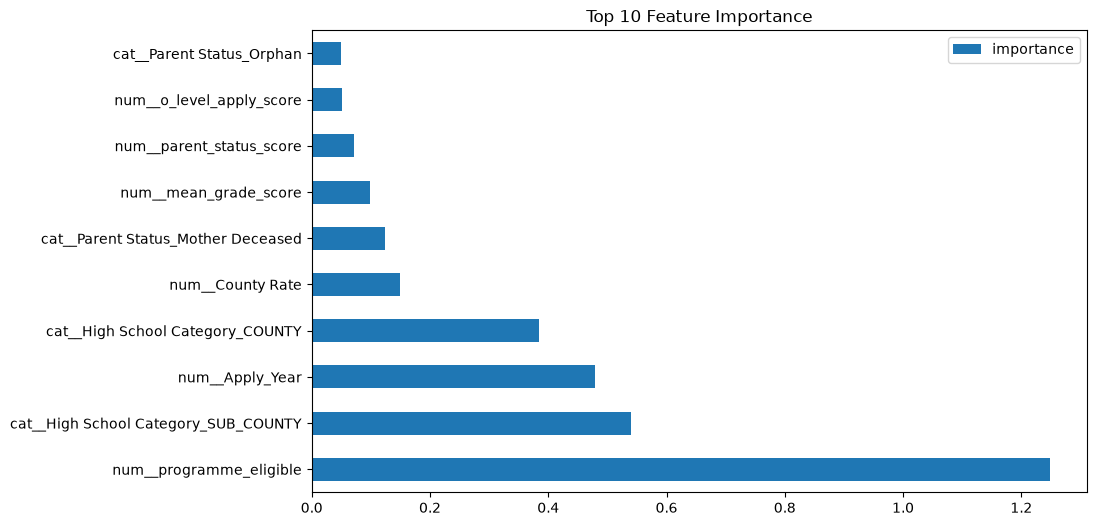

In [1825]:
lr_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

2. We will train using Random Forest and Logistic regression and compare the best model 

In [1826]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_transformed, y_train) #Training
rf_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Since we have train the Random Forest 

Let now evaluate the classifier

In [1827]:
#evaluation of the model 



y_pred_rf = rf_model.predict(X_test_transformed)

In [1828]:
f1_score(y_test, y_pred_rf)

0.6480446927374302

In [1829]:
print(confusion_matrix(y_test, y_pred_rf))

[[103 103]
 [ 86 174]]


In [1830]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.54      0.50      0.52       206
           1       0.63      0.67      0.65       260

    accuracy                           0.59       466
   macro avg       0.59      0.58      0.58       466
weighted avg       0.59      0.59      0.59       466



In [1831]:
rf_df= pd.DataFrame(rf_model.feature_importances_, 
                   columns=['importance'], 
                   index=transformer.get_feature_names_out())
rf_df.sort_values(by='importance', ascending=False)

,importance
num__mean_grade_score,0.285590
num__County Rate,0.206493
num__O LEVEL YEAR,0.151654
num__Apply_Year,0.117632
num__o_level_apply_score,0.083549
num__high_school_category_score,0.038216
num__parent_status_score,0.018067
cat__High School Category_PRIVATE,0.016402
cat__High School Category_NATIONAL,0.015414
cat__Parent Status_Both Parents,0.013483


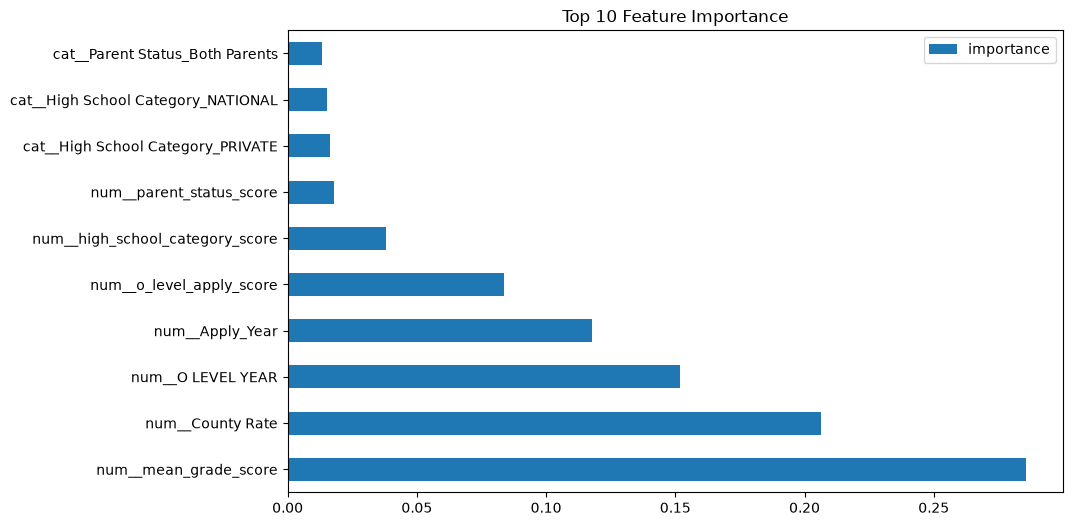

In [1832]:
rf_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

3. XGBoost 

Let train XGBOost

In [1833]:
#let train xgboost model

from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42)

xgb_model.fit(X_transformed, y_train)
xgb_model

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [1834]:
#Let evaluate the XGBoost model

y_pred_xgb = xgb_model.predict(X_test_transformed)


In [1835]:
f1_score(y_test, y_pred_xgb)

0.6702317290552585

In [1836]:
print(confusion_matrix(y_test, y_pred_xgb))

[[ 93 113]
 [ 72 188]]


In [1837]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.56      0.45      0.50       206
           1       0.62      0.72      0.67       260

    accuracy                           0.60       466
   macro avg       0.59      0.59      0.59       466
weighted avg       0.60      0.60      0.60       466



In [1838]:
xgb_df= pd.DataFrame(xgb_model.feature_importances_, 
                   columns=['importance'], 
                   index=transformer.get_feature_names_out())
xgb_df.sort_values(by='importance', ascending=False).head(10)

,importance
num__Apply_Year,0.126936
num__programme_eligible,0.101172
num__mean_grade_score,0.093788
cat__High School Category_PRIVATE,0.080471
num__high_school_category_score,0.076715
num__O LEVEL YEAR,0.076356
cat__Parent Status_Father Deceased,0.069715
num__parent_status_score,0.069315
num__County Rate,0.068708
num__o_level_apply_score,0.068632


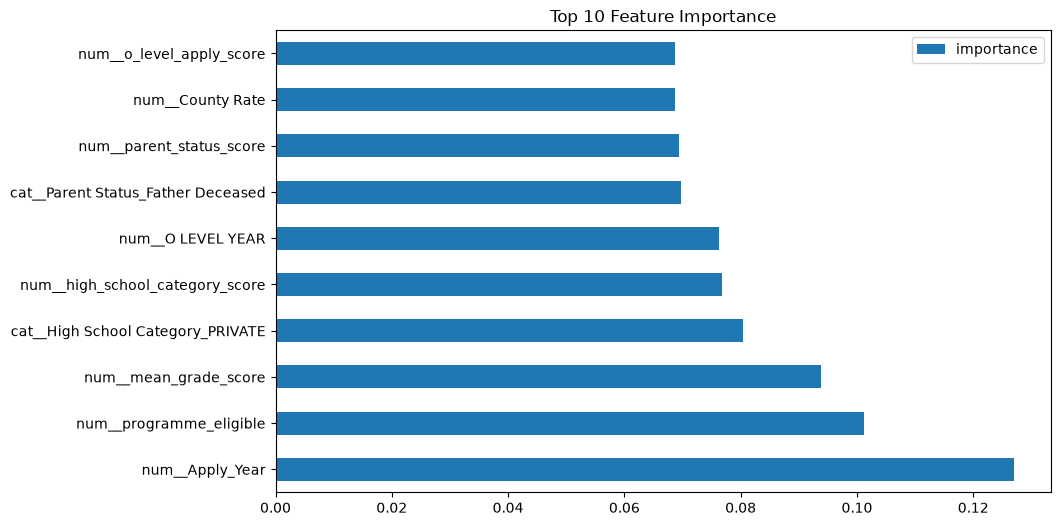

In [1839]:
xgb_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

4. Gradient Boost

In [1840]:
#let train gradient boost

from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_transformed, y_train)

gb_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [1841]:
#Let evaluate the Gradient model

y_pred_gb = gb_model.predict(X_test_transformed)

In [1842]:
f1_score(y_test, y_pred_gb)

0.696551724137931

In [1843]:
print(confusion_matrix(y_test, y_pred_gb))

[[ 88 118]
 [ 58 202]]


In [1844]:
print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           0       0.60      0.43      0.50       206
           1       0.63      0.78      0.70       260

    accuracy                           0.62       466
   macro avg       0.62      0.60      0.60       466
weighted avg       0.62      0.62      0.61       466



In [1845]:
gb_df= pd.DataFrame(gb_model.feature_importances_, 
                   columns=['importance'], 
                   index=transformer.get_feature_names_out())
gb_df.sort_values(by='importance', ascending=False).head(10)

,importance
num__Apply_Year,0.271245
num__mean_grade_score,0.234801
num__O LEVEL YEAR,0.158247
num__County Rate,0.075379
num__high_school_category_score,0.063249
num__o_level_apply_score,0.059934
num__programme_eligible,0.031143
cat__High School Category_PRIVATE,0.029545
cat__Parent Status_Both Parents,0.017692
num__parent_status_score,0.016527


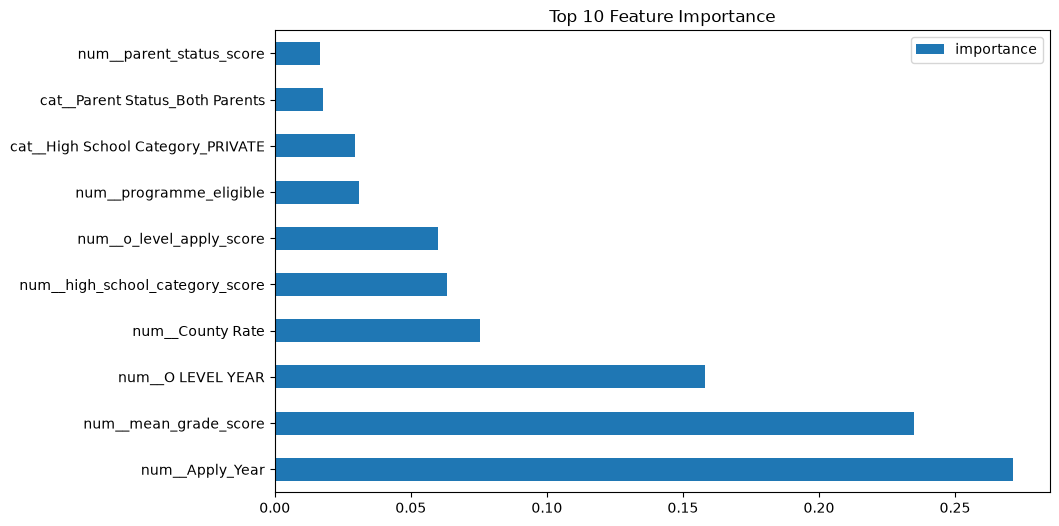

In [1846]:
gb_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

#### Model Comparison

In [1847]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

def evaluate(name, model, X_t, y_t):
    y_pred = model.predict(X_t)
    y_prob = model.predict_proba(X_t)[:,1]
    print(f"\n=== {name} ===")
    print(f" Accuracy  : {accuracy_score(y_t, y_pred):.4f}")
    print(f" Precision : {precision_score(y_t, y_pred, zero_division=0):.4f}")
    print(f"  Recall   : {recall_score(y_t, y_pred, zero_division=0):.4f}")
    print(f"  F1 Score : {f1_score(y_t, y_pred, zero_division=0):.4f}")
    print(f"  AUC-ROC  : {roc_auc_score(y_t, y_prob):.4f}")
    return y_pred






lr_preds = evaluate("Logistic Regression", lr_model, X_test_transformed, y_test)
rf_preds = evaluate("Random Forest", rf_model, X_test_transformed, y_test)
xgb_preds = evaluate("XGBoost", xgb_model, X_test_transformed, y_test)
gradient_preds = evaluate("Gradient Boosting", gb_model, X_test_transformed, y_test)
#svm_preds = evaluate("SVM", svm_model, X_test_transformed, y_test)
#lgbm_preds = evaluate("LightGBM", lightgbm_model, X_test_transformed, y_test)
#catboost_preds = evaluate("CatBoost", catboost_model, X_test_transformed, y_test)
#decisiontree_preds = evaluate("Decision Tree", decisiontree_model, X_test_transformed, y_test)
#naivebayes_preds = evaluate("Naive Bayes", naivebayes_model, X_test_transformed, y_test)



=== Logistic Regression ===
 Accuracy  : 0.6030
 Precision : 0.6113
  Recall   : 0.7923
  F1 Score : 0.6901
  AUC-ROC  : 0.6084

=== Random Forest ===
 Accuracy  : 0.5944
 Precision : 0.6282
  Recall   : 0.6692
  F1 Score : 0.6480


  AUC-ROC  : 0.6092

=== XGBoost ===
 Accuracy  : 0.6030
 Precision : 0.6246
  Recall   : 0.7231
  F1 Score : 0.6702
  AUC-ROC  : 0.6057

=== Gradient Boosting ===
 Accuracy  : 0.6223
 Precision : 0.6312
  Recall   : 0.7769
  F1 Score : 0.6966
  AUC-ROC  : 0.6420


Let Plot these models

In [1848]:
#Model definitions : 

models_config = [ 
    {
        "name" : "Logistic Regression", 
        "model": lr_model, 
        "X": X_test_transformed, 
        "y" : y_test    
    },
    {
        "name" : "Random Forest",
        "model": rf_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "XGBoost",
        "model": xgb_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "Gradient Boosting",
        "model": gb_model,
        "X": X_test_transformed, 
        "y": y_test
    }
]
'''{
        "name" : "SVM",
        "model": svm_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "LightGBM",
        "model": lightgbm_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "CatBoost",
        "model": catboost_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "Decision Tree",
        "model": decisiontree_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "Naive Bayes",
        "model": naivebayes_model,
        "X": X_test_transformed, 
        "y": y_test
    }
]'''


'{\n        "name" : "SVM",\n        "model": svm_model,\n        "X": X_test_transformed, \n        "y": y_test\n    },\n    {\n        "name" : "LightGBM",\n        "model": lightgbm_model,\n        "X": X_test_transformed, \n        "y": y_test\n    },\n    {\n        "name" : "CatBoost",\n        "model": catboost_model,\n        "X": X_test_transformed, \n        "y": y_test\n    },\n    {\n        "name" : "Decision Tree",\n        "model": decisiontree_model,\n        "X": X_test_transformed, \n        "y": y_test\n    },\n    {\n        "name" : "Naive Bayes",\n        "model": naivebayes_model,\n        "X": X_test_transformed, \n        "y": y_test\n    }\n]'

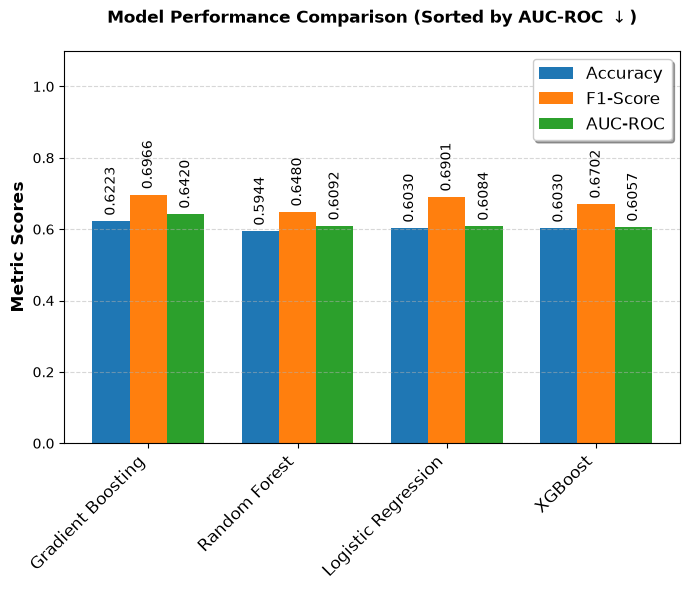

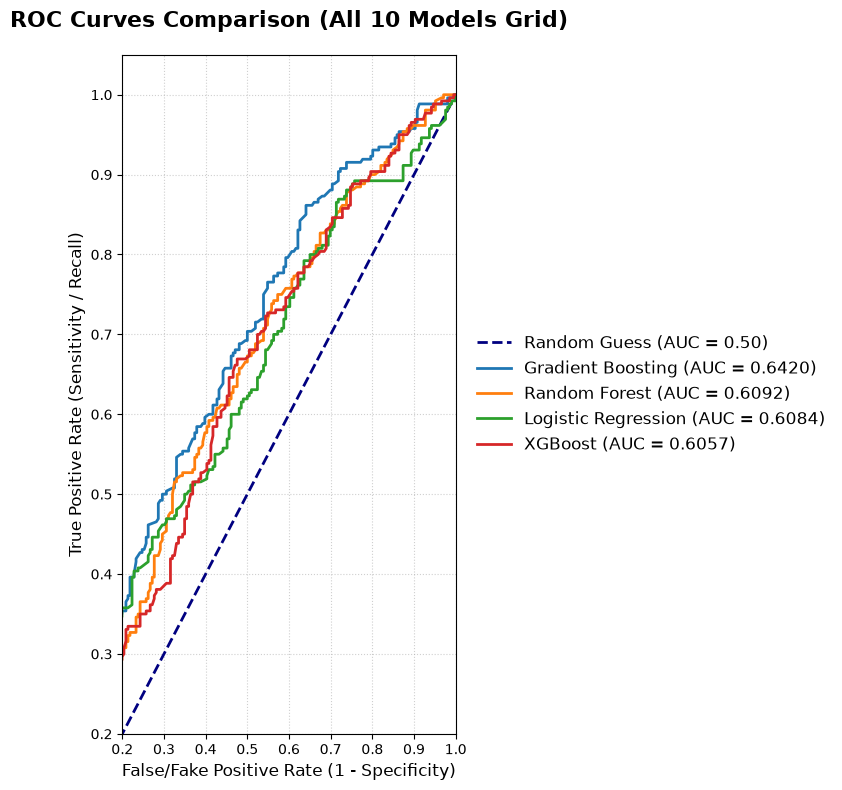

In [1849]:
# 2. Extract metrics and ROC curve data
metrics_list = []
roc_curves_data = {}

for cfg in models_config:
    name = cfg["name"]
    model = cfg["model"]
    X_test = cfg["X"]
    y_test = cfg["y"]

    # Generate predictions and probabilities matching your evaluate function
    # Align X_test with the feature names the model was trained on
    if hasattr(model, "feature_names_in_") and isinstance(X_test, pd.DataFrame):
        X_test = X_test.reindex(columns=model.feature_names_in_, fill_value=0)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    

    # Calculate target comparison metrics
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    metrics_list.append(
        {"Model": name, "Accuracy": acc, "F1-Score": f1, "AUC-ROC": auc}
    )

    # Save ROC curve coordinates
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_curves_data[name] = (fpr, tpr, auc)

# Convert metrics to a DataFrame and sort by AUC-ROC descending for optimal visualization
df_metrics = pd.DataFrame(metrics_list).sort_values(
    by="AUC-ROC", ascending=False
)


# =====================================================================
# VISUALIZATION 1: Side-by-Side Grouped Bar Chart
# =====================================================================
models = df_metrics["Model"].tolist()
x = np.arange(len(models))  # Label locations
width = 0.25  # Width of each metric bar

fig, ax = plt.subplots(figsize=(7, 6))

# Plot the 3 core comparison metrics side-by-side
rects1 = ax.bar(
    x - width, df_metrics["Accuracy"], width, label="Accuracy", color="#1f77b4"
)
rects2 = ax.bar(x, df_metrics["F1-Score"], width, label="F1-Score", color="#ff7f0e")
rects3 = ax.bar(
    x + width, df_metrics["AUC-ROC"], width, label="AUC-ROC", color="#2ca02c"
)

# Style axes and titles to ensure high readability
ax.set_ylabel("Metric Scores", fontsize=12, fontweight="bold")
ax.set_title(
    "Model Performance Comparison (Sorted by AUC-ROC $\\downarrow$)",
    fontsize=12,
    fontweight="bold",
    pad=20,
)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha="right", fontsize=12)
ax.set_ylim(0, 1.1)  # Extra headroom for labels
ax.legend(loc="upper right", fontsize=12, shadow=True)
ax.grid(axis="y", linestyle="--", alpha=0.5)


# Helper function to place value labels vertically above each bar to prevent overlap
def annotate_bars(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f"{height:.4f}",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 4),  # 4 points vertical offset
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            rotation=90,
        )


annotate_bars(rects1)
annotate_bars(rects2)
annotate_bars(rects3)

plt.tight_layout()
#plt.savefig("model_metrics_comparison.png", dpi=300)
#print("Saved: 'model_metrics_comparison.png'")


# =====================================================================
# VISUALIZATION 2: Combined ROC Curve Plot
# =====================================================================
fig, ax = plt.subplots(figsize=(8, 8))

# Plot baseline random guess line
ax.plot(
    [0, 1],
    [0, 1],
    color="navy",
    lw=2,
    linestyle="--",
    label="Random Guess (AUC = 0.50)",
)

# Plot each model's ROC curve using the same descending order from the bar chart
for name in models:
    fpr, tpr, auc = roc_curves_data[name]
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.4f})")

# Format details for professional appearance
ax.set_xlim([0.2, 1.0])
ax.set_ylim([0.2, 1.05])
ax.set_xlabel("False/Fake Positive Rate (1 - Specificity)", fontsize=12)
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
ax.set_title(
    "ROC Curves Comparison (All 10 Models Grid)",
    fontsize=16,
    fontweight="bold",
    pad=20,
)

# Place the legend cleanly outside the main axis box so lines are never covered
ax.legend(
    loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=12, frameon=False
)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
#plt.savefig("model_roc_curves.png", dpi=300)
#print("Saved: 'model_roc_curves.png'")

In [1850]:
gb_model 

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

#### Let create a dictionary

In [1851]:
model_artifacts = {
    "model_name": "Gradient Boosting Classifier",
    "model": gb_model,
    "model_pipeline": transformer,
    "version": "1.0",
    "author": "Julien Ngalo 2026",
}

In [1852]:
type(model_artifacts)

dict

In [1853]:
import joblib 

joblib.dump(
    model_artifacts,
    'awards'

)

['awards']

In [1854]:
#feature importance 

gb_df

,importance
num__O LEVEL YEAR,0.158247
num__Apply_Year,0.271245
num__mean_grade_score,0.234801
num__County Rate,0.075379
num__high_school_category_score,0.063249
num__o_level_apply_score,0.059934
num__parent_status_score,0.016527
num__programme_eligible,0.031143
cat__Parent Status_Both Parents,0.017692
cat__Parent Status_Father Deceased,0.001270


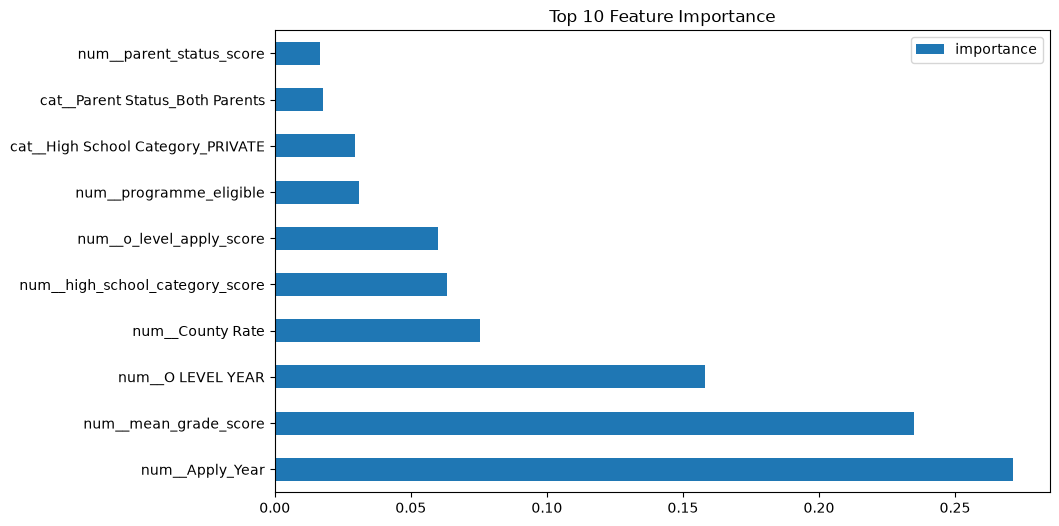

In [1855]:
gb_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

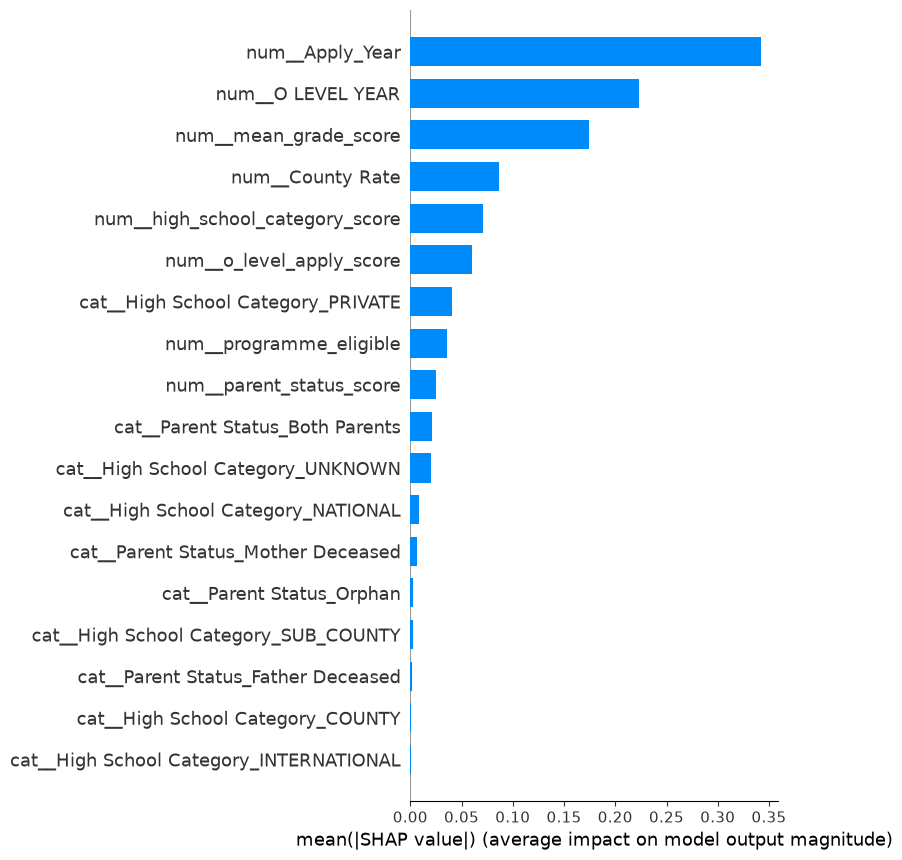

In [1856]:
# Model Explainability for Gradient Boosting

import shap

feature_names = transformer.get_feature_names_out()


explainer = shap.TreeExplainer(gb_model)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=feature_names,
    plot_type='bar'
)



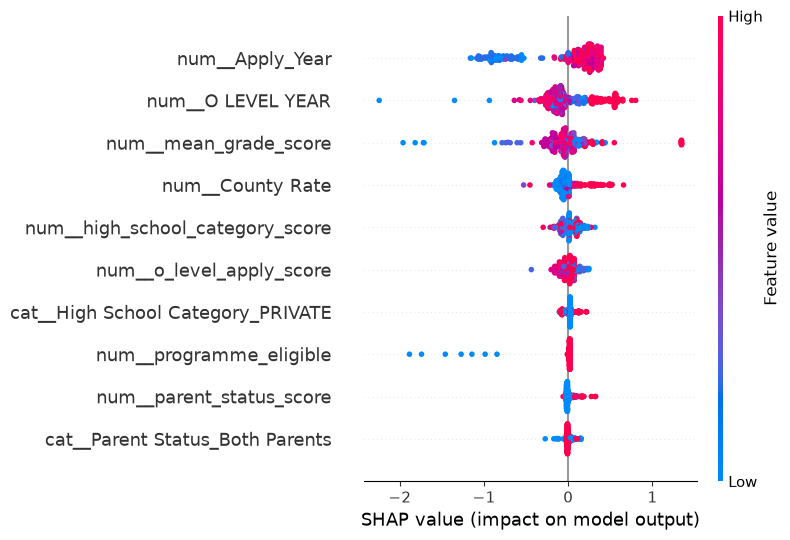

In [1857]:
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=feature_names,
    max_display=10
)

In [1858]:
fa['High School'].value_counts()

High School
Light Academy                    75
Strathmore School                60
Alliance High School             54
Mangu High School                44
Nairobi School                   34
                                 ..
Anestar Secondary Shool           1
Othaya Girls Secondary School     1
Kiserian Junior Seminary          1
NJABINI BOYS HIGH SCHOOL          1
NorthGate School                  1
Name: count, Length: 653, dtype: int64

Removing school may be beneficial for our dataset. 

Let check the 5 fold repetition and see how its behave. 


### Perform five-fold cross-validation

In [1859]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    RobustScaler, OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# =====================================================
# 1. PREPARE ELIGIBLE APPLICANTS
# =====================================================

cv_data = eligible.copy().reset_index(drop=True)
y_cv = cv_data["target"].astype(int)

print("Eligible applicants:", len(cv_data))
print("Target distribution:")
print(y_cv.value_counts())

# Same seven numerical features for both models
numeric_cv = [
    "O LEVEL YEAR",
    "Apply_Year",
    "County Rate",
    "mean_grade_score",
    "high_school_category_score",
    "o_level_apply_score",
    "parent_status_score"
]

categorical_cv = [
    "Parent Status",
    "High School Category"
]

feature_sets = {
    "With School": (
        numeric_cv + categorical_cv + ["School"]
    ),
    "Without School": (
        numeric_cv + categorical_cv
    )
}

# =====================================================
# 2. CREATE MODEL PIPELINE
# =====================================================

def create_cv_pipeline(include_school=True):

    cat_cols = categorical_cv.copy()

    if include_school:
        cat_cols.append("School")

    preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median"
                )),
                ("scaler", RobustScaler())
            ]),
            numeric_cv
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="most_frequent"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            cat_cols
        )
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            random_state=42
        ))
    ])

# =====================================================
# 3. CREATE FIVE STRATIFIED FOLDS
# =====================================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(skf.split(cv_data, y_cv))

results_cv = []

# =====================================================
# 4. TRAIN AND EVALUATE BOTH MODELS
# =====================================================

for fold, (train_idx, test_idx) in enumerate(
    folds, start=1
):

    y_train_cv = y_cv.iloc[train_idx]
    y_test_cv = y_cv.iloc[test_idx]

    for model_name, columns in feature_sets.items():

        model = create_cv_pipeline(
            include_school=(model_name == "With School")
        )

        X_train_cv = cv_data.iloc[train_idx][columns]
        X_test_cv = cv_data.iloc[test_idx][columns]

        # Preprocessing is fitted inside each fold
        model.fit(X_train_cv, y_train_cv)

        probabilities = model.predict_proba(
            X_test_cv
        )[:, 1]

        predictions = (
            probabilities >= 0.50
        ).astype(int)

        # Precision among 50 highest-ranked applicants
        k = min(50, len(probabilities))

        top_indices = np.argsort(
            -probabilities
        )[:k]

        precision_at_50 = (
            y_test_cv.iloc[top_indices].mean()
        )

        results_cv.append({
            "Model": model_name,
            "Fold": fold,
            "Accuracy": accuracy_score(
                y_test_cv, predictions
            ),
            "Precision": precision_score(
                y_test_cv, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_test_cv, predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_test_cv, predictions,
                zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_test_cv, probabilities
            ),
            "Precision@50": precision_at_50
        })

# =====================================================
# 5. DISPLAY FOLD RESULTS
# =====================================================

cv_results = pd.DataFrame(results_cv)

print("\nFIVE-FOLD CROSS-VALIDATION RESULTS")
display(cv_results.round(4))

# =====================================================
# 6. COMPUTE MEAN AND STANDARD DEVIATION
# =====================================================

metric_cols = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Precision@50"
]

cv_mean = (
    cv_results.groupby("Model")[metric_cols]
    .mean()
    .loc[["With School", "Without School"]]
)

cv_std = (
    cv_results.groupby("Model")[metric_cols]
    .std()
    .loc[["With School", "Without School"]]
)

print("\nAVERAGE PERFORMANCE ACROSS FIVE FOLDS")
display(cv_mean.round(4))

print("\nSTANDARD DEVIATION")
display(cv_std.round(4))

# =====================================================
# 7. MEASURE THE DIFFERENCE
# =====================================================

cv_difference = (
    cv_mean.loc["Without School"]
    - cv_mean.loc["With School"]
)

print("\nCHANGE AFTER REMOVING SCHOOL")
display(
    cv_difference.round(4)
    .to_frame("Difference")
)

print("\nHistorical approval rate:",
      round(y_cv.mean(), 4))


Eligible applicants: 2294
Target distribution:
target
1    1287
0    1007
Name: count, dtype: int64



FIVE-FOLD CROSS-VALIDATION RESULTS


,Model,Fold,Accuracy,Precision,Recall,F1,ROC-AUC,Precision@50
0,With School,1,0.6100,0.6312,0.7364,0.6798,0.6499,0.68
1,Without School,1,0.6100,0.6208,0.7868,0.6940,0.6159,0.68
2,With School,2,0.6492,0.6502,0.8140,0.7229,0.7033,0.78
3,Without School,2,0.6536,0.6486,0.8372,0.7310,0.6736,0.76
4,With School,3,0.6209,0.6334,0.7665,0.6937,0.6710,0.74
5,Without School,3,0.6601,0.6507,0.8482,0.7365,0.6614,0.66
6,With School,4,0.6144,0.6258,0.7743,0.6922,0.6599,0.74
7,Without School,4,0.6231,0.6250,0.8171,0.7083,0.6625,0.80
8,With School,5,0.6354,0.6510,0.7549,0.6991,0.6926,0.74
9,Without School,5,0.6332,0.6413,0.7860,0.7063,0.6779,0.78



AVERAGE PERFORMANCE ACROSS FIVE FOLDS


,Accuracy,Precision,Recall,F1,ROC-AUC,Precision@50
Model,,,,,,
With School,0.626,0.6383,0.7692,0.6975,0.6753,0.736
Without School,0.636,0.6373,0.8151,0.7152,0.6582,0.736



STANDARD DEVIATION


,Accuracy,Precision,Recall,F1,ROC-AUC,Precision@50
Model,,,,,,
With School,0.0162,0.0115,0.0288,0.0158,0.0223,0.0358
Without School,0.0209,0.0137,0.0285,0.0179,0.0247,0.0623



CHANGE AFTER REMOVING SCHOOL


,Difference
Accuracy,0.0100
Precision,-0.0010
Recall,0.0459
F1,0.0177
ROC-AUC,-0.0171
Precision@50,0.0000



Historical approval rate: 0.561


### Let do Group Aware Cross Validation

In [1860]:
# STEP 1 — Audit repeated student IDs (run after creating `eligible`)
import numpy as np
import pandas as pd

required_audit = {"ID", "Course", "School", "target"}
missing_audit = required_audit - set(eligible.columns)
if missing_audit:
    raise ValueError(f"Missing required columns: {sorted(missing_audit)}")

ga_data = eligible.copy().reset_index(drop=True)
ga_data["ID"] = ga_data["ID"].astype("string").str.strip()
if ga_data["ID"].isna().any() or ga_data["ID"].eq("").any():
    raise ValueError("Missing/empty student ID detected; resolve before splitting.")

ga_data["target"] = pd.to_numeric(ga_data["target"], errors="raise").astype(int)
if not set(ga_data["target"].unique()).issubset({0, 1}):
    raise ValueError("target must be 0 or 1.")

id_counts = ga_data["ID"].value_counts()
repeated_ids = id_counts[id_counts > 1]
by_id_course = ga_data.groupby(["ID", "Course"], dropna=False)
repeat_id_course = (by_id_course.size() > 1).sum()
conflicting_id_course = (by_id_course["target"].nunique() > 1).sum()

print("Eligible application records:", len(ga_data))
print("Unique students:", ga_data["ID"].nunique())
print("Students with multiple application records:", len(repeated_ids))
print("Rows belonging to repeat students:", int(repeated_ids.sum()))
print("Maximum records per student:", int(id_counts.max()))
print("ID + Course combinations with >1 record:", int(repeat_id_course))
print("ID + Course combinations with conflicting outcomes:", int(conflicting_id_course))

# Optional: inspect repeated applicants locally. Avoid sharing real student IDs.
repeat_details = (ga_data.loc[ga_data["ID"].isin(repeated_ids.index)]
    .groupby("ID").agg(records=("Course", "size"),
                       different_courses=("Course", "nunique"),
                       different_labels=("target", "nunique"))
    .sort_values("records", ascending=False))
display(repeat_details.head(10))

if repeat_id_course or conflicting_id_course:
    print("REVIEW: Some ID + Course pairs repeat or have conflicting statuses."
          " Check legitimate reapplications and join duplication before final training.")


Eligible application records: 2294
Unique students: 2109
Students with multiple application records: 150
Rows belonging to repeat students: 335
Maximum records per student: 3
ID + Course combinations with >1 record: 28
ID + Course combinations with conflicting outcomes: 0


,records,different_courses,different_labels
ID,,,
05b4d3c50909,3,3,2
281fde618d05,3,1,1
1be02002ebe4,3,3,2
1f4873a5e0f5,3,3,2
18e9a0ca8557,3,1,1
1573b4ebebe0,3,1,1
5d73b4b332b7,3,1,1
5de69259b6c8,3,1,1
7df0e897e8fb,3,3,2


REVIEW: Some ID + Course pairs repeat or have conflicting statuses. Check legitimate reapplications and join duplication before final training.


In [1810]:
# STEP 2 — Hold out ~20% of students (not records). Keep this test set untouched.
from sklearn.model_selection import StratifiedGroupKFold

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_position, test_position = next(
    outer.split(ga_data, ga_data["target"], groups=ga_data["ID"])
)

ga_train = ga_data.iloc[train_position].copy().reset_index(drop=True)
ga_test = ga_data.iloc[test_position].copy().reset_index(drop=True)

assert set(ga_train["ID"]).isdisjoint(set(ga_test["ID"]))
assert ga_train["target"].nunique() == 2 and ga_test["target"].nunique() == 2

print("TRAIN records:", len(ga_train), "/ unique students:", ga_train["ID"].nunique(),
      "/ historical approval rate:", round(ga_train["target"].mean(), 4))
print("TEST records:", len(ga_test), "/ unique students:", ga_test["ID"].nunique(),
      "/ historical approval rate:", round(ga_test["target"].mean(), 4))
print("Student ID overlap:", len(set(ga_train["ID"]) & set(ga_test["ID"])))
print("NOTE: StratifiedGroupKFold approximately preserves class ratios,"
      " and the test set may not be exactly 20% of rows.")


TRAIN records: 1835 / unique students: 1683 / historical approval rate: 0.5608
TEST records: 459 / unique students: 426 / historical approval rate: 0.5621
Student ID overlap: 0
NOTE: StratifiedGroupKFold approximately preserves class ratios, and the test set may not be exactly 20% of rows.


In [1811]:
# STEP 3 — Paired group-aware 5-fold CV on the TRAIN portion only
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

numeric_ga = ["O LEVEL YEAR", "Apply_Year", "County Rate", "mean_grade_score",
              "high_school_category_score", "o_level_apply_score", "parent_status_score"]
cat_ga = ["Parent Status", "High School Category"]

for col in numeric_ga:
    ga_train[col] = pd.to_numeric(ga_train[col], errors="coerce")
for col in cat_ga + ["School"]:
    ga_train[col] = ga_train[col].fillna("UNKNOWN").astype(str)

feature_sets_ga = {
    "With School": numeric_ga + cat_ga + ["School"],
    "Without School": numeric_ga + cat_ga,
}

missing = set(feature_sets_ga["With School"]) - set(ga_train.columns)
if missing:
    raise ValueError(f"Missing model features: {sorted(missing)}")


def make_ga_pipeline(include_school):
    cats = cat_ga + (["School"] if include_school else [])
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", RobustScaler())]), numeric_ga),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats)
    ])
    return Pipeline([("preprocessor", prep),
                     ("classifier", GradientBoostingClassifier(random_state=42))])

inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=123)
fold_results_ga = []

for fold, (tr, val) in enumerate(inner.split(
    ga_train, ga_train["target"], groups=ga_train["ID"]), start=1):
    fit_rows = ga_train.iloc[tr]
    val_rows = ga_train.iloc[val]
    assert set(fit_rows["ID"]).isdisjoint(set(val_rows["ID"]))
    actual = val_rows["target"].to_numpy()
    if len(np.unique(actual)) != 2:
        raise ValueError(f"Fold {fold} has only one outcome class; review group balance.")

    for model_name, columns in feature_sets_ga.items():
        model = make_ga_pipeline(include_school=(model_name == "With School"))
        model.fit(fit_rows[columns], fit_rows["target"])
        proba = model.predict_proba(val_rows[columns])[:, list(model.classes_).index(1)]
        predicted = (proba >= 0.5).astype(int)
        top50 = np.argsort(-proba)[:min(50, len(proba))]

        fold_results_ga.append({
            "Fold": fold, "Model": model_name,
            "Train rows": len(fit_rows), "Validation rows": len(val_rows),
            "Accuracy": accuracy_score(actual, predicted),
            "Precision": precision_score(actual, predicted, zero_division=0),
            "Recall": recall_score(actual, predicted, zero_division=0),
            "F1": f1_score(actual, predicted, zero_division=0),
            "ROC-AUC": roc_auc_score(actual, proba),
            "Precision@50": float(actual[top50].mean())
        })

cv_group_results = pd.DataFrame(fold_results_ga)
metric_ga = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Precision@50"]
cv_group_mean = cv_group_results.groupby("Model")[metric_ga].mean().loc[["With School", "Without School"]]
cv_group_std = cv_group_results.groupby("Model")[metric_ga].std().loc[["With School", "Without School"]]
cv_group_diff = (cv_group_mean.loc["Without School"] - cv_group_mean.loc["With School"])

print("FIVE GROUP-AWARE FOLDS — EACH STUDENT APPEARS IN JUST ONE VALIDATION FOLD")
display(cv_group_results.round(4))
print("MEAN")
display(cv_group_mean.round(4))
print("STANDARD DEVIATION")
display(cv_group_std.round(4))
print("WITHOUT SCHOOL minus WITH SCHOOL")
display(cv_group_diff.to_frame("Difference").round(4))
print("The untouched ga_test set was NOT used for model comparison.")


FIVE GROUP-AWARE FOLDS — EACH STUDENT APPEARS IN JUST ONE VALIDATION FOLD


,Fold,Model,Train rows,Validation rows,Accuracy,Precision,Recall,F1,ROC-AUC,Precision@50
0,1,With School,1468,367,0.5967,0.6179,0.7379,0.6726,0.6542,0.76
1,1,Without School,1468,367,0.6022,0.6154,0.7767,0.6867,0.6254,0.66
2,2,With School,1467,368,0.6168,0.6231,0.8068,0.7032,0.6543,0.66
3,2,Without School,1467,368,0.6196,0.6245,0.8116,0.7059,0.6585,0.80
4,3,With School,1469,366,0.6530,0.6598,0.7854,0.7171,0.6894,0.66
5,3,Without School,1469,366,0.6530,0.6423,0.8585,0.7349,0.6361,0.64
6,4,With School,1467,368,0.6440,0.6652,0.7330,0.6975,0.7126,0.76
7,4,Without School,1467,368,0.6603,0.6627,0.8010,0.7253,0.7009,0.74
8,5,With School,1469,366,0.6202,0.6387,0.7415,0.6862,0.6669,0.78
9,5,Without School,1469,366,0.6038,0.6181,0.7659,0.6841,0.6181,0.68


MEAN


,Accuracy,Precision,Recall,F1,ROC-AUC,Precision@50
Model,,,,,,
With School,0.6262,0.6409,0.7609,0.6953,0.6755,0.724
Without School,0.6278,0.6326,0.8027,0.7074,0.6478,0.704


STANDARD DEVIATION


,Accuracy,Precision,Recall,F1,ROC-AUC,Precision@50
Model,,,,,,
With School,0.0225,0.0212,0.0331,0.0169,0.0252,0.0590
Without School,0.0274,0.0198,0.0362,0.0226,0.0334,0.0654


WITHOUT SCHOOL minus WITH SCHOOL


,Difference
Accuracy,0.0016
Precision,-0.0083
Recall,0.0418
F1,0.0120
ROC-AUC,-0.0277
Precision@50,-0.0200


The untouched ga_test set was NOT used for model comparison.
